# 01 데이터 수집

In [2]:
import pandas as pd

industry_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\전주산업단지_정보.xlsx')
population_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\행정안전부_지역별(법정동)성별연령별주민등록인구수_20250531.xlsx')
farm_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\전주시_축사(농장)_20250108.xlsx')
wan_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\2022년~2024년악취민원(전주시 완산구).xlsx')
duck_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\악취민원대장(22년~24년)-전주시 덕진구.xlsx')
weather_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\OBS_ASOS_DD_20250615225403.xlsx')
trash_df = pd.read_excel(r'C:\Users\Admin\Downloads\project\전북특별자치도전주시_폐기물처리시설_20250205.xlsx')

# 02 데이터 전처리

In [4]:
print(industry_df.info())
print('------------------------------------')
print(population_df.info())
print('------------------------------------')
print(farm_df.info())
print('------------------------------------')
print(wan_df.info())
print('------------------------------------')
print(duck_df.info())
print('------------------------------------')
print(weather_df.info())
print('------------------------------------')
print(trash_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   구분         6 non-null      object 
 1   면적(제곱미터)   6 non-null      int64  
 2   위치         6 non-null      object 
 3   주요업종       6 non-null      object 
 4   분양율        6 non-null      object 
 5   조성기간       6 non-null      object 
 6   Latitude   6 non-null      float64
 7   Longitude  6 non-null      float64
dtypes: float64(2), int64(1), object(5)
memory usage: 516.0+ bytes
None
------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Columns: 234 entries, 법정동코드 to Longitude
dtypes: datetime64[ns](1), float64(4), int64(226), object(3)
memory usage: 151.9+ KB
None
------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype         
---

## 1 데이터 정제 

#### a) 완산구 악취민원데이터에서 중요한 위치데이터가 빠짐. 구할 방법이 없기에 해당 행 삭제

In [7]:
wan_df = wan_df.dropna()

#### d) 강수량 데이터에 결측값 존재. 'https://data.kma.go.kr/stcs/grnd/grndRnList.do'에서 24년 12월 비교해본결과 결측값 0임을 파악 나머지도 0이라 유추하여 채움

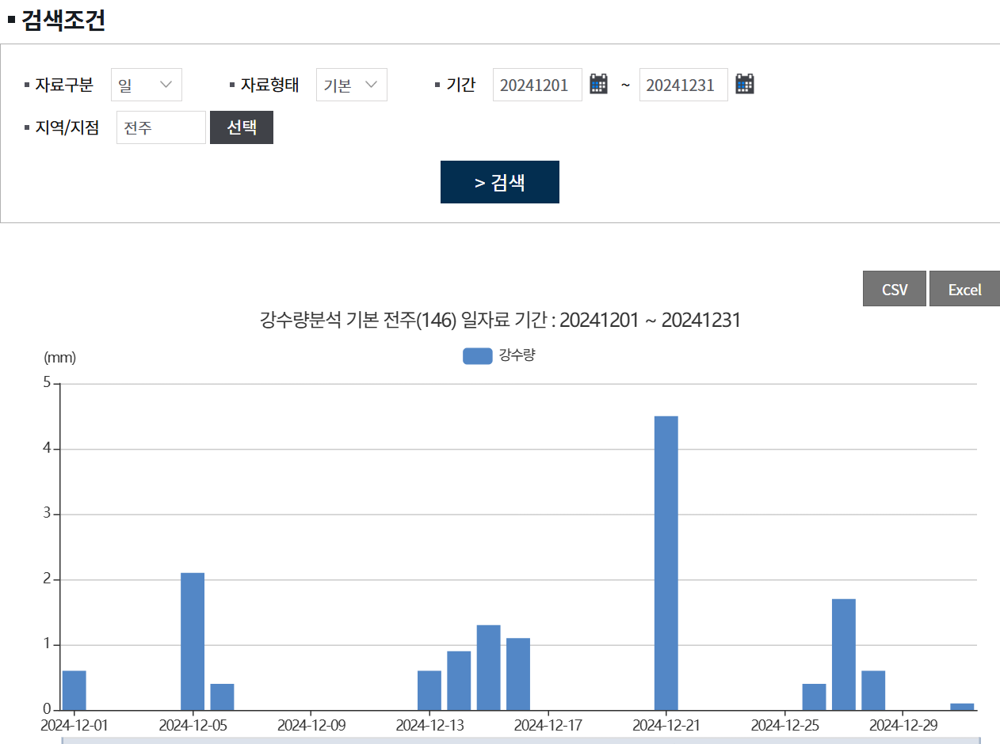

In [10]:
# 특정 열만 0으로 채우기
weather_df['일강수량(mm)'] = weather_df['일강수량(mm)'].fillna(0)
#print(weather_df.info())

#### 추가로 최대 풍속(m/s), 최대 풍속 풍향(16방위), 평균 풍속(m/s)도 결측값 처리 하겠음

In [12]:
df_missing_rows = weather_df[weather_df.isnull().any(axis=1)]
print(df_missing_rows)

      지점 지점명         일시  최저기온(°C)  최고기온(°C)  일강수량(mm)  최대 풍속(m/s)  \
624  146  전주 2023-09-17      22.1      29.1       0.0         NaN   

     최대 풍속 풍향(16방위)  평균 풍속(m/s)  평균 상대습도(%)  평균 해면기압(hPa)  
624             NaN         NaN        85.3        1010.6  


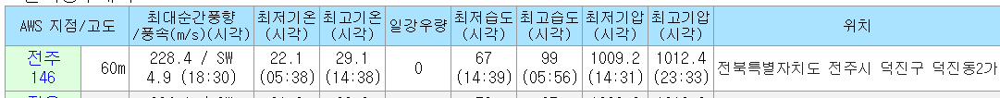

#### 기상청 지역별 상세관측자료에서 데이터 찾음. 단 최대 풍속과 평균 풍속은 찾을 수 없어서 위 순간 풍속으로 대체

In [15]:
weather_df['최대 풍속(m/s)'] = weather_df['최대 풍속(m/s)'].fillna(4.9)
weather_df['최대 풍속 풍향(16방위)'] = weather_df['최대 풍속 풍향(16방위)'].fillna(230) # 16방위여서 230으로 반올림
weather_df['평균 풍속(m/s)'] = weather_df['평균 풍속(m/s)'].fillna(4.9)
print(weather_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   지점              1096 non-null   int64         
 1   지점명             1096 non-null   object        
 2   일시              1096 non-null   datetime64[ns]
 3   최저기온(°C)        1096 non-null   float64       
 4   최고기온(°C)        1096 non-null   float64       
 5   일강수량(mm)        1096 non-null   float64       
 6   최대 풍속(m/s)      1096 non-null   float64       
 7   최대 풍속 풍향(16방위)  1096 non-null   float64       
 8   평균 풍속(m/s)      1096 non-null   float64       
 9   평균 상대습도(%)      1096 non-null   float64       
 10  평균 해면기압(hPa)    1096 non-null   float64       
dtypes: datetime64[ns](1), float64(8), int64(1), object(1)
memory usage: 94.3+ KB
None


#### d) 빈 도로명주소는 지번주소를 토대로 넣기

In [17]:
# 결측값이 있었던 행 정보 확인
trash_df[['시설명', '도로명주소']]

,시설명,도로명주소
0,호동골 쓰레기 매립장,전북특별자치도 전주시 덕진구 동부대로 352-30
1,서신대체 쓰레기 매립장,NaN
2,효자대체 쓰레기 매립장,NaN
3,음식물류폐기물 자원화시설장,전북특별자치도 전주시 완산구 삼산길 51-24
4,재활용선별처리장,전북특별자치도 전주시 완산구 삼산길 51-24
5,전주권 광역1단계 쓰레기매립장,전북특별자치도 완주군 이서면 선비로 1363-92
6,전주권 광역2단계 쓰레기매립장,전북특별자치도 완주군 이서면 선비로 1363-92
7,전주권소각자원센터,전북특별자치도 전주시 완산구 정여립로 625
8,자원순환특화단지,전북특별자치도 전주시 완산구 정여립로 651
9,전주시 종합Recycling-Town,전북특별자치도 전주시 완산구 삼산길 51-24


In [18]:
trash_df.loc[trash_df['시설명'] == '서신대체 쓰레기 매립장', '도로명주소'] = "전북특별자치도 전주시 완산구 선비로 1363-203"
trash_df.loc[trash_df['시설명'] == '효자대체 쓰레기 매립장', '도로명주소'] = '전북특별자치도 전주시 완산구 황강서원로 73'

In [19]:
trash_df['위치'] = trash_df['도로명주소']
trash_df[['시설명', '도로명주소', '위치']]

,시설명,도로명주소,위치
0,호동골 쓰레기 매립장,전북특별자치도 전주시 덕진구 동부대로 352-30,전북특별자치도 전주시 덕진구 동부대로 352-30
1,서신대체 쓰레기 매립장,전북특별자치도 전주시 완산구 선비로 1363-203,전북특별자치도 전주시 완산구 선비로 1363-203
2,효자대체 쓰레기 매립장,전북특별자치도 전주시 완산구 황강서원로 73,전북특별자치도 전주시 완산구 황강서원로 73
3,음식물류폐기물 자원화시설장,전북특별자치도 전주시 완산구 삼산길 51-24,전북특별자치도 전주시 완산구 삼산길 51-24
4,재활용선별처리장,전북특별자치도 전주시 완산구 삼산길 51-24,전북특별자치도 전주시 완산구 삼산길 51-24
5,전주권 광역1단계 쓰레기매립장,전북특별자치도 완주군 이서면 선비로 1363-92,전북특별자치도 완주군 이서면 선비로 1363-92
6,전주권 광역2단계 쓰레기매립장,전북특별자치도 완주군 이서면 선비로 1363-92,전북특별자치도 완주군 이서면 선비로 1363-92
7,전주권소각자원센터,전북특별자치도 전주시 완산구 정여립로 625,전북특별자치도 전주시 완산구 정여립로 625
8,자원순환특화단지,전북특별자치도 전주시 완산구 정여립로 651,전북특별자치도 전주시 완산구 정여립로 651
9,전주시 종합Recycling-Town,전북특별자치도 전주시 완산구 삼산길 51-24,전북특별자치도 전주시 완산구 삼산길 51-24


#### e) 덕진구 민원처리결과에서 결측값 확인. 상태를 알수없기에 미해결로 채움

In [21]:
duck_df['민원 처리 결과'] = duck_df['민원 처리 결과'].fillna('미해결')
duck_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163 entries, 0 to 162
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   민원 발생 일시   163 non-null    object 
 1   위치         163 non-null    object 
 2   민원 내용      163 non-null    object 
 3   민원 처리 결과   163 non-null    object 
 4   Latitude   163 non-null    float64
 5   Longitude  163 non-null    float64
 6   해결유무       163 non-null    object 
 7   세부분류       163 non-null    object 
dtypes: float64(2), object(6)
memory usage: 10.3+ KB


## 2 데이터 통합

#### 완산구 데이터와 덕진구 데이터 통합

In [24]:
complaint_df = pd.concat([wan_df, duck_df], ignore_index=True)
complaint_df

,민원 발생 일시,위치,민원 내용,민원 처리 결과,Latitude,Longitude,해결유무,세부분류
0,2022-01-04 00:00:00,전주시 완산구 우림로 971 인근,보름에 한번씩 우림로 971 근방 알 수 없는 곳에서 쓰레기를 태우는 악취 발생,우림로 971 근방에서 소각한 흔적을 찾기 어려웠음,35.776232,127.099785,미해결,비신고 악취시설 - 공장/보일러/소각
1,2022-01-10 00:00:00,전주시 완산구 덕적골2길 35-18 플러스리버하임 아파트 옆 지하주차장,덕적골2길 35-18 평화동 플러스리버하임 아파트 옆 지하주차장에서 경유냄새가 올라...,"현지출장하여 관리사무소(063-282-6481)에 민원내용 전달, 일시적 정전으로 ...",35.795054,127.141579,해결,비신고 악취시설 - 공장/보일러/소각
2,2022-01-17 00:00:00,전주시 완산구 삼천동1가 585-2,삼천동1가 585-2 쌍용재건축 공사로인한 민원,공사관계자에게 행정지도하였음,35.799785,127.123848,해결,비신고 악취시설 - 공장/보일러/소각
3,2022-01-20 00:00:00,전주시 완산구 서부시장 크리스탈 주차장,서부시장 크리스탈 주차장 고기구워먹고 불피움 냄새남 컨테이너 박스에서,"현지출장하여 취식행위 하지않도록 계도조치 후, 민원인과 통화하여 계도조치 완료 안내함",35.795512,127.132447,해결,생활악취시설 - 음식점/생활시설
4,2022-01-22 00:00:00,전주시 완산구 동서학동 대아산성아파트 근처 풀공장,동서학동 대아산성아파트 근처 풀공장 악취민원,"현장방문했으나, 공장에 관리인 부재 및 가동하지 않고있는 상태로 악취확인 불가",35.804501,127.156278,미해결,비신고 악취시설 - 공장/보일러/소각
...,...,...,...,...,...,...,...,...
304,2022.11.08.,전주시 덕진구 송이네(건산3길 24),송이네 음식점 환풍시설이 주거지 창문으로 향하여 음식냄새 들어옴.,음식점 방문하여 환풍시설 방향 확인하였으나 해당 주거지로 들어가지 않았음. 환풍시설...,35.833032,127.141670,해결,생활악취시설 - 음식점/생활시설
305,2022.11.15.,전주시 덕진구 송천동,송천동 일대 악취.,정확한 주소지를 알려주지 않았으므로 답변만 해드림.,35.880135,127.114651,미해결,기타 - 원인불명
306,2022.11.11.,전주시 덕진구 산내들 숯불갈비(모래내1길 6),"산내들 갈비냄새로 인한 숯, 연탄탄내.",후드 및 환풍기 청결하게 관리해달라고 말씀드림.,35.834143,127.140393,해결,생활악취시설 - 음식점/생활시설
307,2022.11.23.,전주시 덕진구 빅센헤어,빅센헤어 약품냄새가 복도쪽 환풍기를 통해 뿜어져나옴.,복도측 건물 출입구를 열어서 환풍을 수시로 해달라고 말씀드림.,35.856025,127.155339,해결,생활악취시설 - 음식점/생활시설


In [25]:
complaint_df.to_excel("project\전주시_민원데이터_2022~2024.xlsx", index=False, engine='openpyxl')

complaint_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   민원 발생 일시   309 non-null    object 
 1   위치         309 non-null    object 
 2   민원 내용      309 non-null    object 
 3   민원 처리 결과   309 non-null    object 
 4   Latitude   309 non-null    float64
 5   Longitude  309 non-null    float64
 6   해결유무       309 non-null    object 
 7   세부분류       309 non-null    object 
dtypes: float64(2), object(6)
memory usage: 19.4+ KB


#### a) 민원 데이터의 민원발생일시와 날씨데이터를 통합

In [27]:
import pandas as pd

# 통일
#duck_df['민원 발생 일시'] = pd.to_datetime(duck_df['민원 발생 일시'], errors='coerce')

complaint_df['날짜'] = pd.to_datetime(complaint_df['민원 발생 일시'])
weather_df['날짜'] = pd.to_datetime(weather_df['일시'])

# 공통 날짜만 골라서 병합
test_df = pd.merge(complaint_df, weather_df, on='날짜', how='inner')

# 그냥 통합
T_test_df = pd.merge(weather_df, complaint_df, on='날짜', how='left')
T_test_df.to_excel("project\전주시_날씨_2022~2024.xlsx", index=False, engine='openpyxl')

# 결과 출력
#print("공통 날짜 개수:", len(test_df))
#print(test_df.head())
print(test_df.info())
print(T_test_df.info()) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   민원 발생 일시        292 non-null    object        
 1   위치              292 non-null    object        
 2   민원 내용           292 non-null    object        
 3   민원 처리 결과        292 non-null    object        
 4   Latitude        292 non-null    float64       
 5   Longitude       292 non-null    float64       
 6   해결유무            292 non-null    object        
 7   세부분류            292 non-null    object        
 8   날짜              292 non-null    datetime64[ns]
 9   지점              292 non-null    int64         
 10  지점명             292 non-null    object        
 11  일시              292 non-null    datetime64[ns]
 12  최저기온(°C)        292 non-null    float64       
 13  최고기온(°C)        292 non-null    float64       
 14  일강수량(mm)        292 non-null    float64       
 15  최대 풍속(

#### b) 산업단지, 인구밀도, 축사 데이터를 통합

In [29]:
industry_df['분류'] = '산업단지'
population_df['분류'] = '인구밀도'
farm_df['분류'] = '축사'
wan_df['분류'] = '완산구 민원'
duck_df['분류'] = '덕진구 민원'
trash_df['분류'] = '페기물처리시설'
complaint_df['분류'] = '전주시 민원'
#print(industry_df.head())
#print(population_df.head())
#print(farm_df.head())
#print(complaint_df.head())
#print(trash_df.head())
#print(wan_df.head())
#print(duck_df.head())

In [30]:
import pandas as pd
# 데이터프레임 합치기 (행 방향으로)
posion_df = pd.concat([industry_df, population_df, farm_df, complaint_df, trash_df], ignore_index=True)

# 엑셀 파일로 저장
posion_df.to_excel("project\위도_경도.xlsx", index=False, engine='openpyxl')
#print(posion_df.head())

## 3 데이터 축소

#### a) 통합후 필요 데이터만 뽑기

In [33]:
posion_df = posion_df[['분류', '위치', 'Latitude', 'Longitude', '민원 내용', '민원 처리 결과']]
#print(posion_df)

#### b) 통합 후 중복되는 열 삭제

In [35]:
test_df = test_df.drop('민원 발생 일시', axis=1)
test_df = test_df.drop('일시', axis=1)

print(test_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   위치              292 non-null    object        
 1   민원 내용           292 non-null    object        
 2   민원 처리 결과        292 non-null    object        
 3   Latitude        292 non-null    float64       
 4   Longitude       292 non-null    float64       
 5   해결유무            292 non-null    object        
 6   세부분류            292 non-null    object        
 7   날짜              292 non-null    datetime64[ns]
 8   지점              292 non-null    int64         
 9   지점명             292 non-null    object        
 10  최저기온(°C)        292 non-null    float64       
 11  최고기온(°C)        292 non-null    float64       
 12  일강수량(mm)        292 non-null    float64       
 13  최대 풍속(m/s)      292 non-null    float64       
 14  최대 풍속 풍향(16방위)  292 non-null    float64       
 15  평균 풍속(

#### c) 민원내용의 세부분류 수작업

#### d) 민원결과에 대한 해결여부 수작업

## 4 데이터 변환

#### 위도와 경도가 필요하기에 구글 엑셀을 통해 구함

#### a) 세부분류 숫자로 변화

In [41]:
import pandas as pd

# 세부분류 → 숫자 매핑 정의
mapping = {
    "기타 - 기타 제조": 1,
    "기타 - 원인불명": 2,
    "비신고 악취시설 - 공장/보일러/소각": 3,
    "생활악취시설 - 농경지/비료": 4,
    "생활악취시설 - 쓰레기/하수": 5,
    "생활악취시설 - 음식점/생활시설": 6,
    "생활악취시설 - 가축분뇨/축사": 7
}

# 세부분류 코드 컬럼 추가
complaint_df["세부분류_코드"] = complaint_df["세부분류"].map(mapping)
test_df["세부분류_코드"] = test_df["세부분류"].map(mapping)
T_test_df["세부분류_코드"] = T_test_df["세부분류"].map(mapping)
T_test_df["세부분류_코드"] = T_test_df["세부분류_코드"].fillna('0')

# 결과 확인
print(complaint_df[["세부분류", "세부분류_코드"]].head())
print(test_df[["세부분류", "세부분류_코드"]].head())
print(T_test_df[["세부분류", "세부분류_코드"]].head())


                   세부분류  세부분류_코드
0  비신고 악취시설 - 공장/보일러/소각        3
1  비신고 악취시설 - 공장/보일러/소각        3
2  비신고 악취시설 - 공장/보일러/소각        3
3     생활악취시설 - 음식점/생활시설        6
4  비신고 악취시설 - 공장/보일러/소각        3
                   세부분류  세부분류_코드
0  비신고 악취시설 - 공장/보일러/소각        3
1  비신고 악취시설 - 공장/보일러/소각        3
2  비신고 악취시설 - 공장/보일러/소각        3
3     생활악취시설 - 음식점/생활시설        6
4  비신고 악취시설 - 공장/보일러/소각        3
                   세부분류 세부분류_코드
0                   NaN       0
1                   NaN       0
2                   NaN       0
3  비신고 악취시설 - 공장/보일러/소각     3.0
4     생활악취시설 - 음식점/생활시설     6.0


#### b) 해결여부 해결= 0과 미해결= 1로 표현

In [43]:
# '해결유무' 열을 숫자로 변환하는 함수 정의
def convert_resolution(value):
    if isinstance(value, str):
        if value.strip() == '해결':
            return 0
        elif value.strip() == '미해결':
            return 1
    return None  # 값이 없거나 예상과 다르면 None 처리

# 새로운 열 추가
complaint_df["해결"] = complaint_df["해결유무"].apply(convert_resolution)
test_df["해결"] = test_df["해결유무"].apply(convert_resolution)

# 결과 미리보기
print(complaint_df[['해결유무',"해결"]].head())
print(test_df[['해결유무',"해결"]].head())

# 데이터 저장
test_df.to_excel("project\민원_날씨_통합.xlsx", index=False, engine='openpyxl')

  해결유무  해결
0  미해결   1
1   해결   0
2   해결   0
3   해결   0
4  미해결   1
  해결유무  해결
0  미해결   1
1   해결   0
2   해결   0
3   해결   0
4  미해결   1


#### c) 민원여부 0과1로 나누기 민원없음=0, 있음=1

In [45]:
# 1. 민원건수 집계 (날짜별)
T_test_df['민원건수'] = T_test_df.groupby('날짜')['세부분류'].transform('count')

# 2. 결측치(민원 없는 날) 처리
T_test_df['민원건수'] = T_test_df['민원건수'].fillna(0)

# 3. 민원 발생 여부 (0 = 없음, 1 = 있음)
T_test_df['민원발생여부'] = (T_test_df['민원건수'] > 0).astype(int)

print(T_test_df.head())
# 결측값 리리
T_test_df.fillna(0, inplace=True)

# 데이터 저장
T_test_df.to_excel("project\민원여부_날씨_통합.xlsx", index=False, engine='openpyxl')

    지점 지점명         일시  최저기온(°C)  최고기온(°C)  일강수량(mm)  최대 풍속(m/s)  \
0  146  전주 2022-01-01      -8.9       2.7       0.0         1.8   
1  146  전주 2022-01-02      -4.2       6.6       0.0         3.4   
2  146  전주 2022-01-03      -5.6       3.8       0.0         2.4   
3  146  전주 2022-01-04      -2.5       5.2       0.0         3.5   
4  146  전주 2022-01-04      -2.5       5.2       0.0         3.5   

   최대 풍속 풍향(16방위)  평균 풍속(m/s)  평균 상대습도(%)  ...                  위치  \
0           340.0         0.8        52.5  ...                 NaN   
1           320.0         1.3        59.8  ...                 NaN   
2           340.0         1.2        66.9  ...                 NaN   
3           270.0         1.6        55.3  ...  전주시 완산구 우림로 971 인근   
4           270.0         1.6        55.3  ...   전주시 덕진구 인후동2가 ***   

                                          민원 내용  \
0                                           NaN   
1                                           NaN   
2                      

# 03 탐색적 데이터 분석

In [47]:
import matplotlib.pyplot as plt
import matplotlib as mpl
# 'Malgun Gothic' (맑은 고딕) 사용
plt.rcParams['font.family'] = 'Malgun Gothic'
# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

#### a) 민원건수와 계절, 요일, 월별

C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\2045981434.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(subset=['날짜', 'Latitude', 'Longitude'], inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\2045981434.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['날짜'] = pd.to_datetime(df['날짜'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\2045981434.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

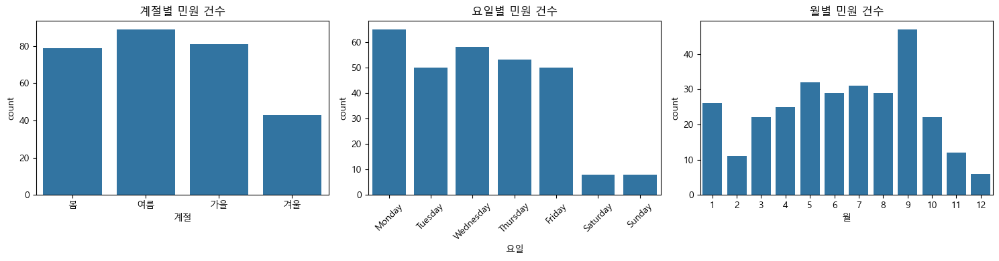

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# ----------------------------
# 1. 데이터 불러오기 및 전처리
# ----------------------------
df = test_df  # 파일명은 실제 경로에 맞게 수정
df = df[['날짜', '위치', 'Latitude', 'Longitude', '세부분류']]
df.dropna(subset=['날짜', 'Latitude', 'Longitude'], inplace=True)
df['날짜'] = pd.to_datetime(df['날짜'])

# 시간 정보 추가
df['월'] = df['날짜'].dt.month
df['요일'] = df['날짜'].dt.day_name()
df['계절'] = df['월'].apply(lambda x: '봄' if x in [3,4,5] else 
                                      '여름' if x in [6,7,8] else 
                                      '가을' if x in [9,10,11] else '겨울')

# ----------------------------
# 2. 시간 분석 시각화
# ----------------------------
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.countplot(data=df, x='계절', order=['봄','여름','가을','겨울'])
plt.title('계절별 민원 건수')

plt.subplot(1, 3, 2)
sns.countplot(data=df, x='요일', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.title('요일별 민원 건수')
plt.xticks(rotation=45)

plt.subplot(1, 3, 3)
sns.countplot(data=df, x='월')
plt.title('월별 민원 건수')

plt.tight_layout()
plt.show()

### 종합 분석
전주시 악취 민원은 여름철과 9월에 집중되며, 겨울에는 가장 적게 발생한다.
요일별로는 월요일에 민원이 가장 많고, 주말에는 현저히 적다.
이는 악취 발생이 기후와 계절, 민원 접수 시스템과 밀접하게 관련 있음을 보여준다.
특히 여름과 환절기에 고온·다습한 조건과 농작업 증가로 악취 민감도가 높아진다.
월요일 민원 집중은 주말 누적된 불편사항이 반영된 결과로 보인다.
따라서 여름~가을 집중 대응체계와 주말 민원 대응 시스템 강화가 필요하다.

#### b) 민원과 기상 요소

C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\1099845044.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\1099845044.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['날짜'] = pd.to_datetime(df['날짜'])


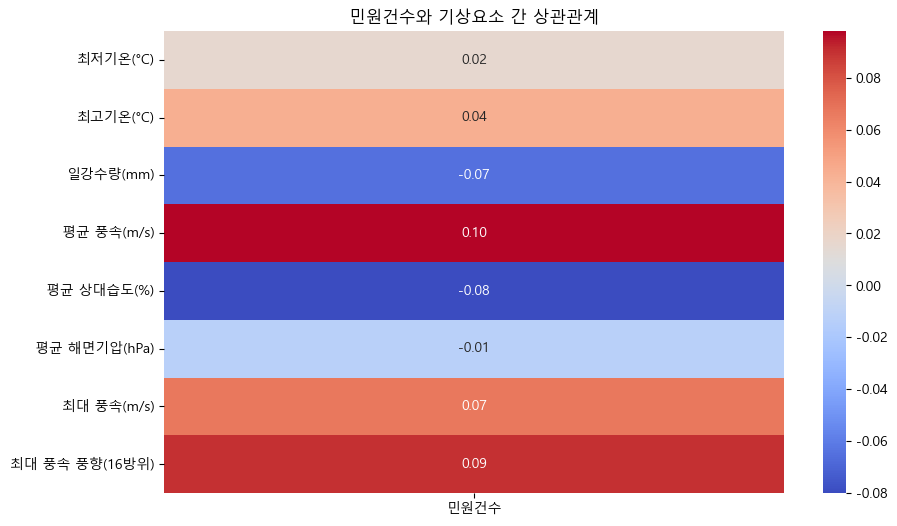

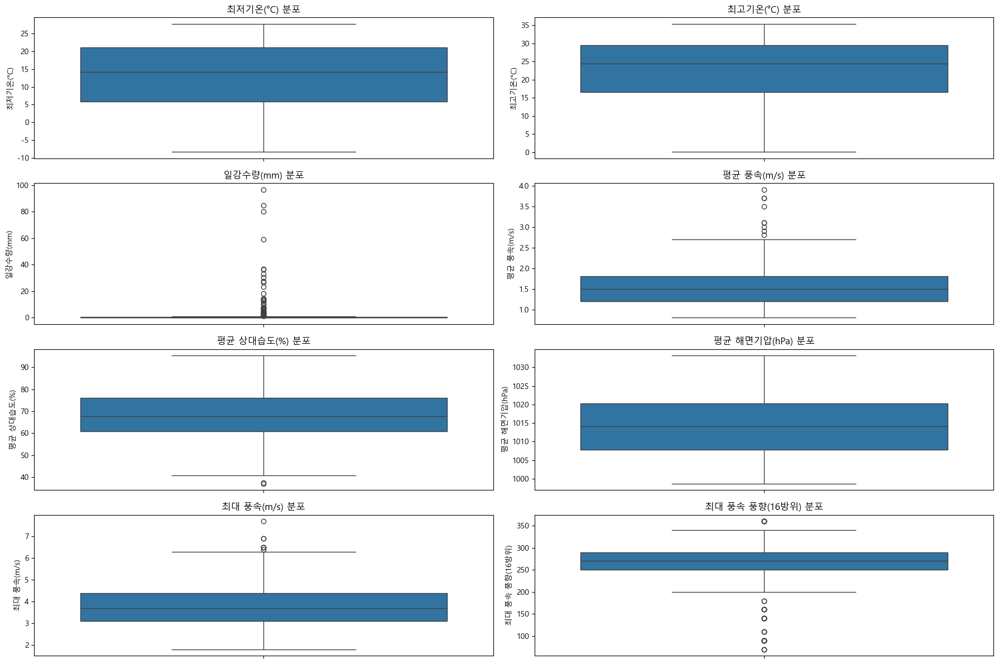

In [52]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. 데이터 불러오기
df = test_df

# 2. 필요한 열만 추출 및 결측치 제거
df = df[[
    '날짜', 'Latitude', 'Longitude', '세부분류',
    '최저기온(°C)', '최고기온(°C)', '일강수량(mm)',
    '평균 풍속(m/s)', '평균 상대습도(%)', '평균 해면기압(hPa)', "최대 풍속(m/s)", "최대 풍속 풍향(16방위)"
]]
df.dropna(inplace=True)
df['날짜'] = pd.to_datetime(df['날짜'])

# 3. 날짜별 민원 건수 집계
daily_counts = df.groupby('날짜').size().reset_index(name='민원건수')

# 4. 날짜별 평균 기상 정보 집계
weather_avg = df.groupby('날짜')[[
    '최저기온(°C)', '최고기온(°C)', '일강수량(mm)',
    '평균 풍속(m/s)', '평균 상대습도(%)', '평균 해면기압(hPa)', "최대 풍속(m/s)", "최대 풍속 풍향(16방위)"
]].mean().reset_index()

# 5. 민원건수와 날씨 정보 병합
df_eda = pd.merge(daily_counts, weather_avg, on='날짜')

# 6. 상관관계 분석 및 시각화
corr = df_eda.corr(numeric_only=True)

plt.figure(figsize=(10, 6))
sns.heatmap(corr[['민원건수']].drop('민원건수'), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("민원건수와 기상요소 간 상관관계")
plt.show()

# 7. 기상요소별 분포 확인 (Boxplot)
variables = ['최저기온(°C)', '최고기온(°C)', '일강수량(mm)', '평균 풍속(m/s)', '평균 상대습도(%)', '평균 해면기압(hPa)', "최대 풍속(m/s)", "최대 풍속 풍향(16방위)"]

plt.figure(figsize=(18, 12))
for i, var in enumerate(variables, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(data=df_eda, y=var)
    plt.title(f'{var} 분포')

plt.tight_layout()
plt.show()

### 종합 해석 
전주시 악취 민원은 기상 요소와 밀접한 상관관계를 보인다.
특히 평균 풍속과 최대 풍속은 민원건수와 양의 상관관계를 보여, 바람이 강할수록 악취 확산 가능성이 크다.
반면, 해면기압은 민원건수와 음의 상관관계를 보여, 기압이 낮을수록 악취 발생 민원이 많았다.
기온, 습도, 강수량 등은 민원과 뚜렷한 상관관계를 보이지 않거나 낮은 상관도를 나타냈다.
Boxplot 분포에 따르면, 풍향은 특정 방향으로 치우쳐 있고, 풍속과 기온 변수는 전반적으로 일정한 분포를 가지며,
일강수량은 이상치(outlier)가 많은 특징을 보였다.
이를 통해 풍속·기압 기반의 악취 민원 예측 가능성이 확인되며, 향후 바람 데이터 활용한 사전 대응 체계 구축이 필요하다.

#### b-1) 풍향별 민원발생 빈도

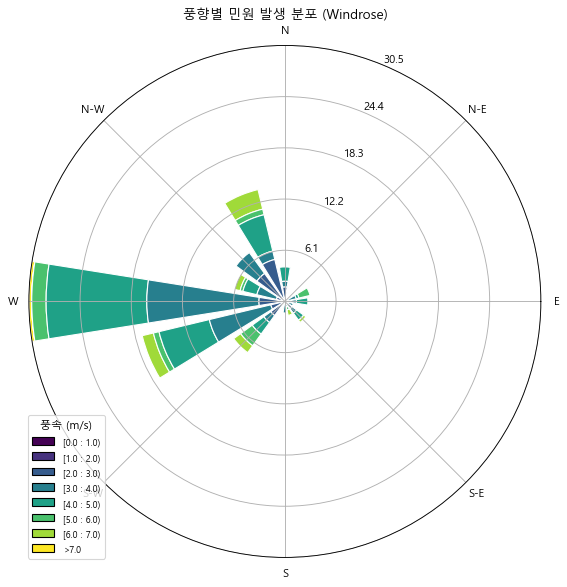

In [55]:
import pandas as pd
from windrose import WindroseAxes
import matplotlib.pyplot as plt
import numpy as np

# 1. 데이터 준비
df = test_df.copy()
df = df[['최대 풍속(m/s)', '최대 풍속 풍향(16방위)']].dropna()

# 풍향(방위각) 컬럼 이름 변경 for windrose compatibility
wind_speed = df['최대 풍속(m/s)']
wind_dir = df['최대 풍속 풍향(16방위)']

# 2. Windrose 시각화
ax = WindroseAxes.from_ax()
ax.bar(wind_dir, wind_speed, normed=True, opening=0.8, edgecolor='white', bins=np.arange(0, 8, 1))
ax.set_legend(title="풍속 (m/s)")
plt.title("풍향별 민원 발생 분포 (Windrose)")
plt.show()


### Windrose 분석 결과
악취 민원은 서풍(W) 방향일 때 가장 많이 발생하였으며,
그 외에도 북서풍(NW)과 남서풍(SW) 방향에서도 민원이 다수 분포했다.
이는 서쪽에서 바람이 불어올 때 민원 발생 지역에 악취가 집중된다는 것을 의미한다.
바람의 세기는 대부분 2-6 m/s 사이에 집중되었으며,
일부 민원은 강풍 구간(>6 m/s)에서도 발생해 확산 가능성을 시사한다.
동풍·남풍 계열(E-S)에서는 민원 발생 비중이 매우 낮았다.
이는 서쪽에 악취 유발원이 존재하고 있음을 강하게 시사한다.
민원 대응 시 풍향과 풍속을 기반으로 유입 경로 추적이 필요하다.
특히, 서풍일 때 집중 모니터링 및 현장 점검 강화가 효과적일 수 있다.
Windrose 분석은 기상 조건 기반 악취 대응 전략 수립에 매우 유용한 도구임이 확인되었다.

#### b-2) 당일 기상에 따른 민원횟수

C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\199256306.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot_table = complaint_df.groupby([y, x])["민원발생여부"].count().unstack()
C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\199256306.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot_table = complaint_df.groupby([y, x])["민원발생여부"].count().unstack()
C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\199256306.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True

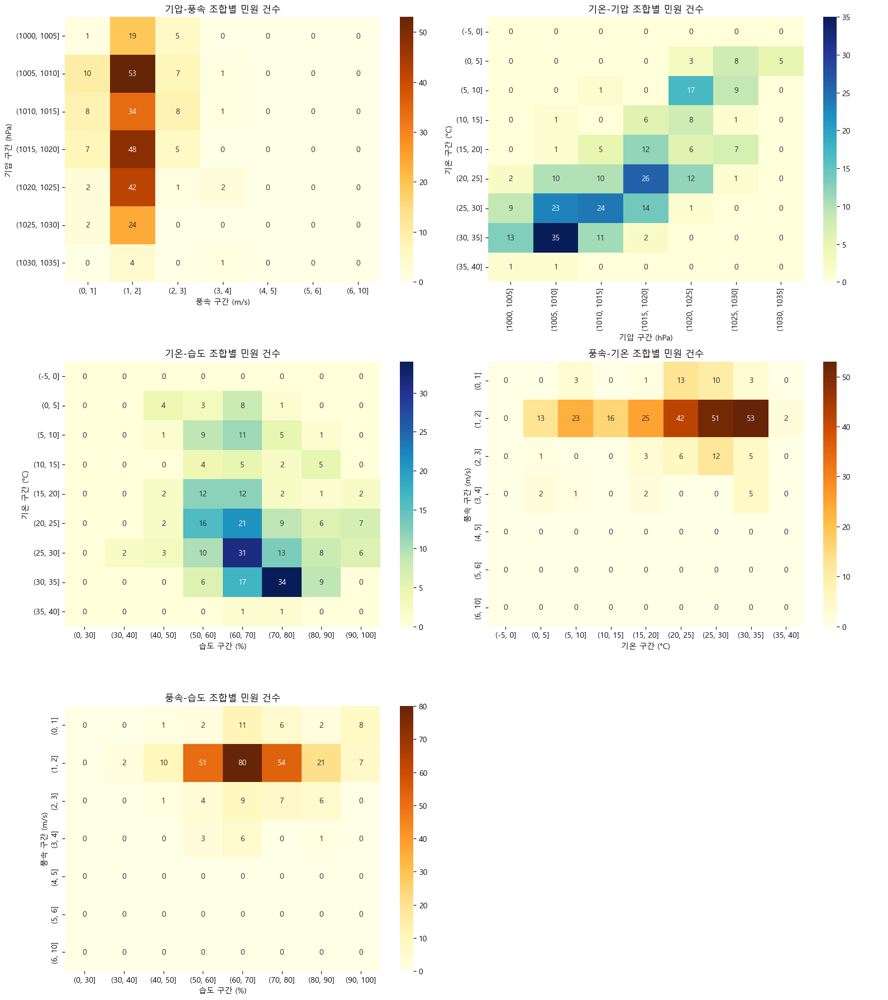

In [58]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

complaint_df = T_test_df[T_test_df["민원발생여부"] == 1].copy()

# 구간 설정
complaint_df["풍속구간"] = pd.cut(complaint_df["평균 풍속(m/s)"], bins=[0, 1, 2, 3, 4, 5, 6, 10])
complaint_df["기온구간"] = pd.cut(complaint_df["최고기온(°C)"], bins=[-5, 0, 5, 10, 15, 20, 25, 30, 35, 40])
complaint_df["기압구간"] = pd.cut(complaint_df["평균 해면기압(hPa)"], bins=[1000, 1005, 1010, 1015, 1020, 1025, 1030, 1035])
complaint_df["습도구간"] = pd.cut(complaint_df["평균 상대습도(%)"], bins=[0, 30, 40, 50, 60, 70, 80, 90, 100])

# subplot 히트맵 시각화
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 각 히트맵 조합
heatmap_settings = [
    ("기압구간", "풍속구간", "기압-풍속 조합별 민원 건수", "풍속 구간 (m/s)", "기압 구간 (hPa)", "YlOrBr"),
    ("기온구간", "기압구간", "기온-기압 조합별 민원 건수", "기압 구간 (hPa)", "기온 구간 (°C)", "YlGnBu"),
    ("기온구간", "습도구간", "기온-습도 조합별 민원 건수", "습도 구간 (%)", "기온 구간 (°C)", "YlGnBu"),
    ("풍속구간", "기온구간", "풍속-기온 조합별 민원 건수", "기온 구간 (°C)", "풍속 구간 (m/s)", "YlOrBr"),
    ("풍속구간", "습도구간", "풍속-습도 조합별 민원 건수", "습도 구간 (%)", "풍속 구간 (m/s)", "YlOrBr")
]

# 히트맵 그리기
for i, (y, x, title, xlabel, ylabel, cmap) in enumerate(heatmap_settings):
    r, c = divmod(i, 2)
    pivot_table = complaint_df.groupby([y, x])["민원발생여부"].count().unstack()
    sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap=cmap, ax=axes[r][c])
    axes[r][c].set_title(title)
    axes[r][c].set_xlabel(xlabel)
    axes[r][c].set_ylabel(ylabel)

# 빈 칸 없애기
axes[2][1].axis("off")
plt.tight_layout()
plt.show()


### 종합분석
악취 민원은 풍속 1-2m/s, 습도 60-70%, 기온 25-30℃, 기압 1010-1020hPa 조건에서 가장 많이 발생했다.
특히 고온다습하면서 바람이 약하고 기압이 높은 날, 공기정체로 인해 악취가 퍼지지 않고 머무르는 현상이 두드러진다.
기온이 높고 습한 날일수록 냄새 민감도와 불쾌감도 높아진다.
반면, 풍속이 3m/s 이상이거나 기온이 낮거나 건조한 조건에서는 민원이 적었다.
즉, 악취 민원은 “더운 날 + 바람 약할 때 + 습도 높을 때” 집중되는 패턴이 명확하다.
따라서 해당 조합 조건 발생 시 모니터링 강화, 사전 경고, 민감지역 순찰이 효과적이다.

#### c) 민원위치와 축사, 산업단지와의 거리

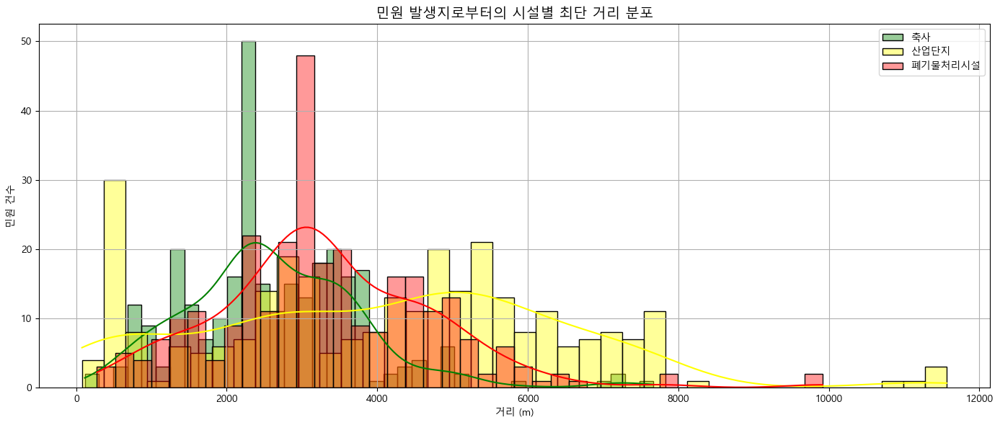

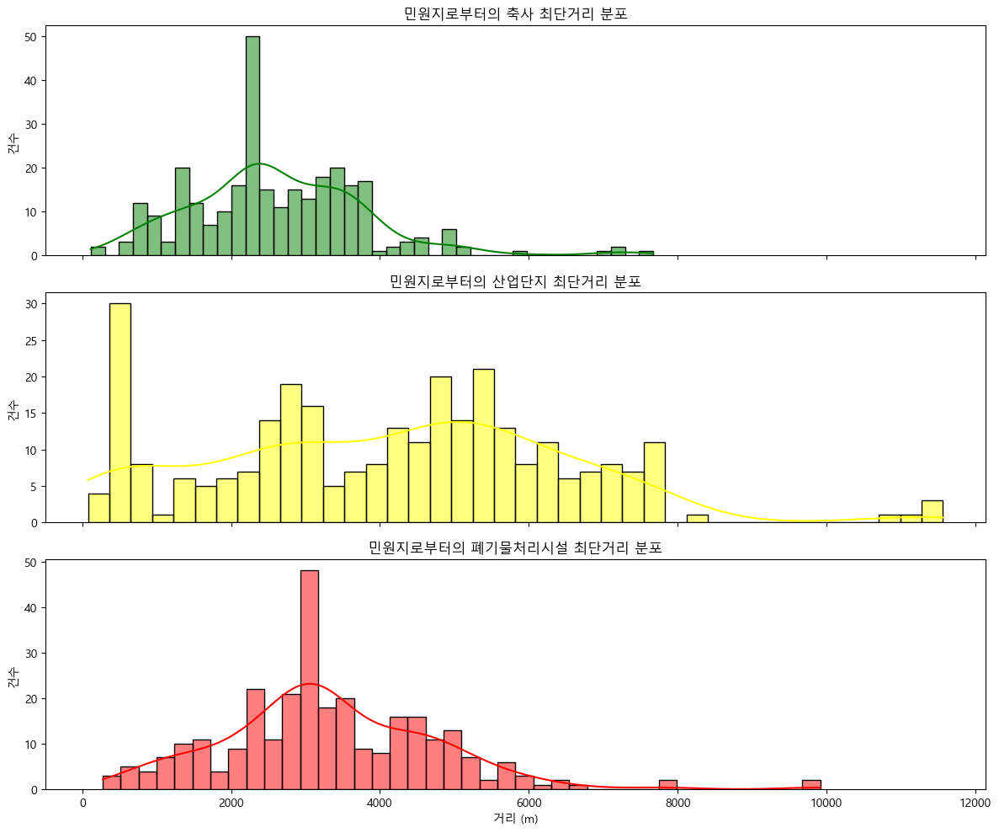

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from geopy.distance import geodesic

# 재정의: 이미 불러온 데이터프레임 사용
df_m = complaint_df.copy()
df_f = farm_df.copy()
df_i = industry_df.copy()
df_t = trash_df.copy()

# 위도/경도 컬럼 정리
df_m = df_m.rename(columns={'위도': 'Latitude', '경도': 'Longitude'})
df_f = df_f.rename(columns={'위도': 'Latitude', '경도': 'Longitude'})
df_i = df_i.rename(columns={'위도': 'Latitude', '경도': 'Longitude'})
df_t = df_t.rename(columns={'위도': 'Latitude', '경도': 'Longitude'})

# 결측값 제거
df_m = df_m.dropna(subset=['Latitude', 'Longitude'])
df_f = df_f.dropna(subset=['Latitude', 'Longitude'])
df_i = df_i.dropna(subset=['Latitude', 'Longitude'])
df_t = df_t.dropna(subset=['Latitude', 'Longitude'])

# 최단 거리 계산 함수
def compute_min_distances(from_points, to_points):
    return [min([geodesic(src, dst).meters for dst in to_points]) for src in from_points]

# 민원 좌표 및 대상 좌표 추출
complaints = list(zip(df_m['Latitude'], df_m['Longitude']))
farms = list(zip(df_f['Latitude'], df_f['Longitude']))
industries = list(zip(df_i['Latitude'], df_i['Longitude']))
trashes = list(zip(df_t['Latitude'], df_t['Longitude']))

# 거리 계산 및 컬럼 추가
df_m['축사_최단거리(m)'] = compute_min_distances(complaints, farms)
df_m['산업단지_최단거리(m)'] = compute_min_distances(complaints, industries)
df_m['폐기물처리시설_최단거리(m)'] = compute_min_distances(complaints, trashes)

# 시각화
plt.figure(figsize=(14, 6))
sns.histplot(df_m['축사_최단거리(m)'], bins=40, kde=True, color='green', label='축사', alpha=0.4)
sns.histplot(df_m['산업단지_최단거리(m)'], bins=40, kde=True, color='yellow', label='산업단지', alpha=0.4)
sns.histplot(df_m['폐기물처리시설_최단거리(m)'], bins=40, kde=True, color='red', label='폐기물처리시설', alpha=0.4)

plt.title("민원 발생지로부터의 시설별 최단 거리 분포", fontsize=14)
plt.xlabel("거리 (m)")
plt.ylabel("민원 건수")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

sns.histplot(df_m['축사_최단거리(m)'], bins=40, kde=True, color='green', ax=axes[0])
axes[0].set_title('민원지로부터의 축사 최단거리 분포')
axes[0].set_ylabel('건수')

sns.histplot(df_m['산업단지_최단거리(m)'], bins=40, kde=True, color='yellow', ax=axes[1])
axes[1].set_title('민원지로부터의 산업단지 최단거리 분포')
axes[1].set_ylabel('건수')

sns.histplot(df_m['폐기물처리시설_최단거리(m)'], bins=40, kde=True, color='red', ax=axes[2])
axes[2].set_title('민원지로부터의 폐기물처리시설 최단거리 분포')
axes[2].set_xlabel('거리 (m)')
axes[2].set_ylabel('건수')

plt.tight_layout()
plt.show()

### 종합 요약
악취 민원은 폐기물처리시설, 산업단지, 축사 모두에서 2-5km 이내 거리에서 집중적으로 발생했다.
폐기물처리시설은 약 3000m 부근, 축사는 2500m 부근, 산업단지는 2000-6000m 사이에서 민원 빈도가 높았다.
축사의 경우 가까운 거리일수록 민원이 많고, 먼 거리에서는 급감하는 경향을 보였다.
산업단지는 넓은 반경에서 민원이 분산되며, 일부 1000m 이내 인접 지역에서도 민원이 발생했다.
이는 악취가 직접적 거리보다는 바람 방향·지형 등 복합 요인에 따라 확산됨을 시사한다.
세 유형 모두 생활권과 일정 거리 이상 겹치는 지점에서 민원이 집중되는 패턴을 보인다.
결론적으로, 적절한 거리 확보와 풍향 고려한 입지 선정이 악취 민원 저감에 중요하다.

#### d) 인구 밀도와 민원의 관계

In [64]:
import shapefile
import folium
from folium import Rectangle
from pyproj import Transformer
import pandas as pd
from branca.element import Template, MacroElement

# 1. 좌표계 변환기 생성
transformer = Transformer.from_crs("EPSG:5186", "EPSG:4326", always_xy=True)

# 2. 인구 데이터 준비
pop_df = population_df[["읍면동명", "인구수(계)"]].copy()
pop_df.columns = ["법정동명", "총인구수"]
pop_df["법정동명"] = pop_df["법정동명"].str.strip()
pop_grouped = pop_df.groupby("법정동명")["총인구수"].sum().reset_index()

# 3. Shapefile 읽기
sf1 = shapefile.Reader(r'C:\Users\Admin\Downloads\project\한국국토정보공사_LX맵_읍면동 전주시 완산구_20240401\52111.shp')
sf2 = shapefile.Reader(r'C:\Users\Admin\Downloads\project\한국국토정보공사_LX맵_읍면동 전주시 덕진구_20240401\52113.shp')

fields = [field[0] for field in sf1.fields[1:]]
features = []

def append_features(sf, features):
    for sr in sf.shapeRecords():
        atr = dict(zip(fields, sr.record))
        geom = sr.shape.__geo_interface__

        # 좌표 변환
        if geom["type"] == "Polygon":
            coords = [[transformer.transform(x, y) for x, y in ring] for ring in geom["coordinates"]]
        elif geom["type"] == "MultiPolygon":
            coords = [[[transformer.transform(x, y) for x, y in ring] for ring in poly] for poly in geom["coordinates"]]
        geom["coordinates"] = coords

        # 인구수 매핑
        dong = atr["EMD_NM"].strip()
        pop_row = pop_grouped[pop_grouped["법정동명"] == dong]
        atr["총인구수"] = int(pop_row["총인구수"].values[0]) if not pop_row.empty else None

        features.append({"type": "Feature", "geometry": geom, "properties": atr})
    return features

# 두 구의 feature 추가
features = append_features(sf1, features)
features = append_features(sf2, features)

geojson_data = {"type": "FeatureCollection", "features": features}

# 4. 지도 생성
center = geojson_data["features"][0]["geometry"]["coordinates"][0][0]
m = folium.Map(location=[center[1], center[0]], zoom_start=12)

# 5. 인구수에 따른 색상 설정 함수
def get_color(pop):
    if pop is None:
        return "#cccccc"
    elif pop > 40000:
        return "#004d00"
    elif pop > 35000:
        return "#006600"
    elif pop > 30000:
        return "#008000"
    elif pop > 25000:
        return "#00b300"
    elif pop > 20000:
        return "#00cc44"
    elif pop > 15000:
        return "#33cc33"
    elif pop > 10000:
        return "#66ff66"
    elif pop > 5000:
        return "#99ff99"
    elif pop > 1000:
        return "#ccffcc"
    else:
        return "#f2fff2"

# 6. 인구 밀도 지도 그리기
folium.GeoJson(
    geojson_data,
    name="전주시 인구 밀도",
    style_function=lambda feature: {
        "fillColor": get_color(feature["properties"]["총인구수"]),
        "color": "black",
        "weight": 1,
        "fillOpacity": 0.7
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["EMD_NM", "총인구수"],
        aliases=["법정동", "총인구수"],
        localize=True
    )
).add_to(m)

# 7. 민원 위치 중복 집계
rounded_coords = complaint_df.dropna(subset=["Latitude", "Longitude"]).copy()
rounded_coords["lat_rounded"] = rounded_coords["Latitude"].round(4)
rounded_coords["lon_rounded"] = rounded_coords["Longitude"].round(4)
location_counts = rounded_coords.groupby(["lat_rounded", "lon_rounded"]).size().reset_index(name="count")

# 8. 바차트(사각형) 추가
height_scale = 0.0004
width_scale = 0.0003

for _, row in location_counts.iterrows():
    lat, lon, count = row["lat_rounded"], row["lon_rounded"], row["count"]
    height = count * height_scale
    bounds = [[lat, lon], [lat + height, lon + width_scale]]
    Rectangle(
        bounds=bounds,
        color="red",
        fill=True,
        fill_opacity=0.7,
        tooltip=f"{count}건 민원"
    ).add_to(m)

# 축사 마커 추가 (파란색 cow 아이콘)
for _, row in farm_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="blue", icon="paw", prefix="fa"),
        tooltip=row["업체명"] if "업체명" in row else "축사"
    ).add_to(m)

# 산업단지 마커 추가 (보라색 industry 아이콘)
for _, row in industry_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="purple", icon="industry", prefix="fa"),
        tooltip=row["구분"] if "구분" in row else "산업단지"
    ).add_to(m)

# 페기물처리시설 마커 추가 (보라색 industry 아이콘)
for _, row in trash_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="gray", icon="trash", prefix="fa"),
        tooltip=row["시설명"] if "시설명" in row else "페기물처리시설"
    ).add_to(m)

# 9. 범례 추가
legend_html = """
{% macro html(this, kwargs) %}
<div style='
    position: fixed;
    bottom: 50px;
    left: 50px;
    width: 230px;
    height: 360px;
    background-color: white;
    border:2px solid grey;
    z-index:9999;
    font-size:14px;
    padding: 10px;
'>
<b>인구수 범례 (초록)</b><br>
<i style='background:#004d00;width:18px;height:18px;float:left;margin-right:8px;'></i> > 40,000<br>
<i style='background:#006600;width:18px;height:18px;float:left;margin-right:8px;'></i> > 35,000<br>
<i style='background:#008000;width:18px;height:18px;float:left;margin-right:8px;'></i> > 30,000<br>
<i style='background:#00b300;width:18px;height:18px;float:left;margin-right:8px;'></i> > 25,000<br>
<i style='background:#00cc44;width:18px;height:18px;float:left;margin-right:8px;'></i> > 20,000<br>
<i style='background:#33cc33;width:18px;height:18px;float:left;margin-right:8px;'></i> > 15,000<br>
<i style='background:#66ff66;width:18px;height:18px;float:left;margin-right:8px;'></i> > 10,000<br>
<i style='background:#99ff99;width:18px;height:18px;float:left;margin-right:8px;'></i> > 5,000<br>
<i style='background:#ccffcc;width:18px;height:18px;float:left;margin-right:8px;'></i> > 1,000<br>
<i style='background:#f2fff2;width:18px;height:18px;float:left;margin-right:8px;'></i> ≤ 1,000<br><br>
<b>기타 마커</b><br>
<i style='color:red;' class='fa fa-square'></i> 민원 바 차트<br>
<i style='color:blue;' class='fa fa-paw'></i> 축사 위치<br>
<i style='color:purple;' class='fa fa-industry'></i> 산업단지 위치<br>
<i style='color:gray;' class='fa fa-trash'></i> 폐기물처리시설 위치<br>
</div>
{% endmacro %}
"""
legend = MacroElement()
legend._template = Template(legend_html)
m.get_root().add_child(legend)

# 10. 지도 저장
m.save("/mnt/data/전주시_인구+민원_bar차트_최종.html")
m

### 종합 해석 문장
인구 밀집 지역은 전주시 중심부로, 짙은 초록색으로 표시된다.
민원은 중심 시가지뿐 아니라 일부 외곽 지역에서도 다수 발생한다.
붉은 사각형 바 차트는 동일 위치에서 발생한 중복 민원을 시각화한다.
축사(파란 발자국 아이콘)는 덕진구 북부 외곽에 집중 분포되어 있다.
산업단지(보라색 공장 아이콘)는 덕진구 서부에 모여 있으며, 인근에 민원도 많다.
폐기물처리시설(회색 쓰레기통 아이콘)은 완산구 남부에 밀집되어 있다.
폐기물처리시설 주변에서도 민원이 높게 나타난다.
일부 축사 주변은 인구는 적지만 민원이 집중되어 있어 환경 영향이 의심된다.
산업·축산·폐기물 관련 시설과 민원 간의 지리적 연관성이 시각적으로 드러난다.
정책적으로 민원 다발 지역과 환경 유해시설 주변에 대한 우선적 관리가 필요하다.

#### f) 세부 분류별 건수

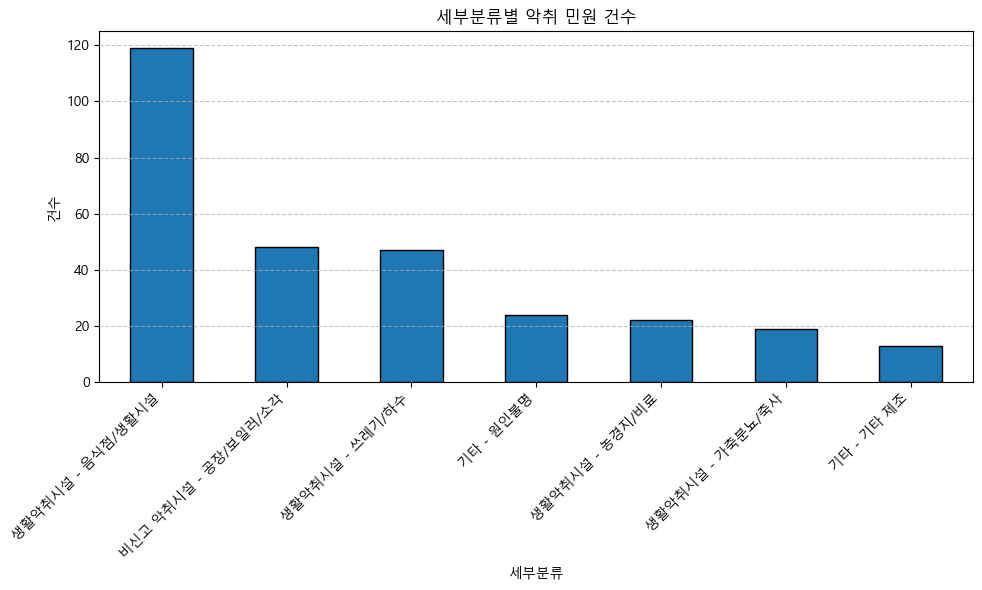

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# 2. 세부분류별 민원 건수 계산
category_counts = complaint_df["세부분류"].value_counts()

# 3. 막대그래프 그리기
plt.figure(figsize=(10, 6))
category_counts.plot(kind='bar', edgecolor='black')
plt.title("세부분류별 악취 민원 건수")
plt.xlabel("세부분류")
plt.ylabel("건수")
plt.xticks(rotation=45, ha='right')  # X축 레이블 회전
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### 분석해석
생활악취시설 - 음식점/생활시설이 가장 많은 민원 발생 원인으로 확인되었습니다.
공장/보일러/소각과 쓰레기/하수 관련 민원도 높은 비중을 차지했습니다.
기타 - 원인불명 항목이 많아, 구체적인 분류가 어려운 민원이 상당수 존재합니다.
농경지/비료와 축사 관련 악취는 상대적으로 적지만 꾸준히 발생하고 있습니다.
기타 제조 관련 민원은 적은 편이지만 일부 지역에서 보고되고 있습니다.
민원 분포는 생활환경과 산업시설의 밀집도와 밀접한 관련이 있는 것으로 보입니다.
향후 분류 체계의 정교화와 현장 조사의 강화가 필요합니다.

#### g) 세부분류와 기상

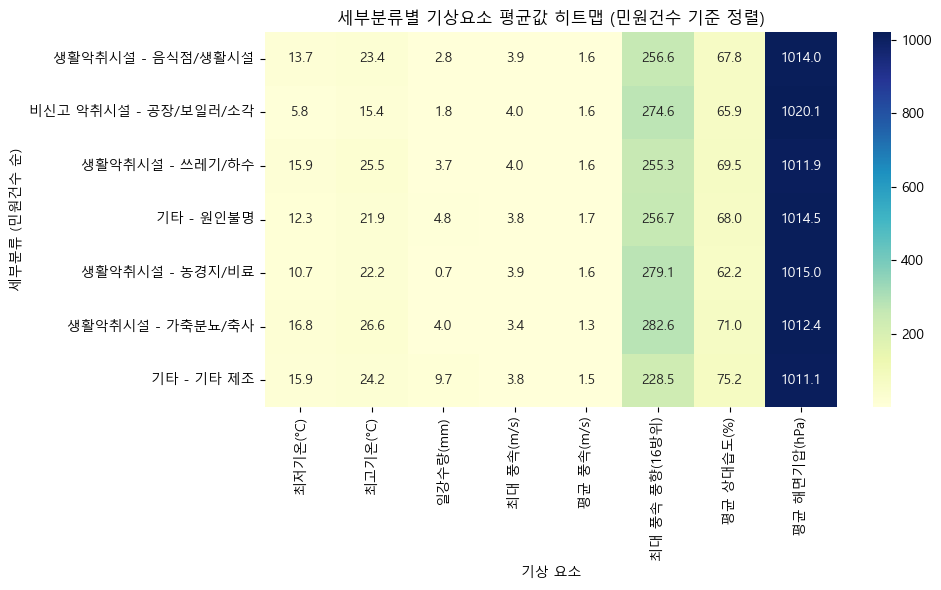

In [70]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 사용할 열
selected_cols = [
    "세부분류", "최저기온(°C)", "최고기온(°C)", "일강수량(mm)",
    "최대 풍속(m/s)", "평균 풍속(m/s)", "최대 풍속 풍향(16방위)",
    "평균 상대습도(%)", "평균 해면기압(hPa)"
]

# 결측값 제거
df_valid = test_df[selected_cols].dropna()

# 1. 세부분류별 기상 평균값 계산
category_weather_avg = df_valid.groupby("세부분류").mean(numeric_only=True)

# 2. 세부분류별 민원건수 계산
complaint_count = df_valid["세부분류"].value_counts().rename("민원건수")

# 3. 두 데이터 결합 (인덱스 기준 join)
weather_with_count = category_weather_avg.join(complaint_count)

# 4. 히트맵 시각화: y축을 민원건수로 정렬
sorted_data = weather_with_count.sort_values("민원건수", ascending=False).drop(columns="민원건수")

plt.figure(figsize=(10, 6))
sns.heatmap(sorted_data, annot=True, cmap="YlGnBu", fmt=".1f")
plt.title("세부분류별 기상요소 평균값 히트맵 (민원건수 기준 정렬)")
plt.ylabel("세부분류 (민원건수 순)")
plt.xlabel("기상 요소")
plt.tight_layout()
plt.show()


### 종합 요약 해석
공장/보일러/소각 악취는 낮은 기온과 비교적 강한 바람에서 많이 발생합니다.
음식점/생활시설 악취는 평균적인 기온·풍속·습도에서 고르게 발생합니다.
쓰레기/하수 악취는 비가 거의 오지 않고 습도가 중간인 날에 자주 나타납니다.
농경지/비료 악취는 강수량이 매우 낮은 건조한 날에 집중됩니다.
가축분뇨/축사 악취는 더운 날씨와 높은 습도, 약한 바람에서 강하게 퍼집니다.
기타 제조 및 원인불명 악취는 기온과 기압은 평범하지만 풍속이 낮고 공기 정체 시 감지됩니다.
전반적으로 풍속이 약할수록 냄새가 더 쉽게 머무르거나 확산되어 민원이 증가합니다.
강수량이 낮고, 습도와 온도가 높을수록 악취 감지 가능성이 커집니다.
민원 유형별로 기상조건에 따라 악취 인지 패턴이 뚜렷하게 다르게 나타납니다.
기상요소를 고려한 시간대별 대응이나 사전 점검이 효과적일 수 있습니다.

#### h) 세부분류별 월, 요일, 계절 상관관계

<Figure size 1200x600 with 0 Axes>

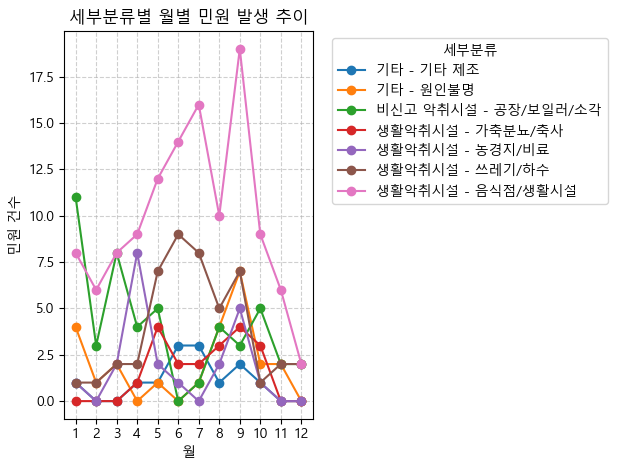

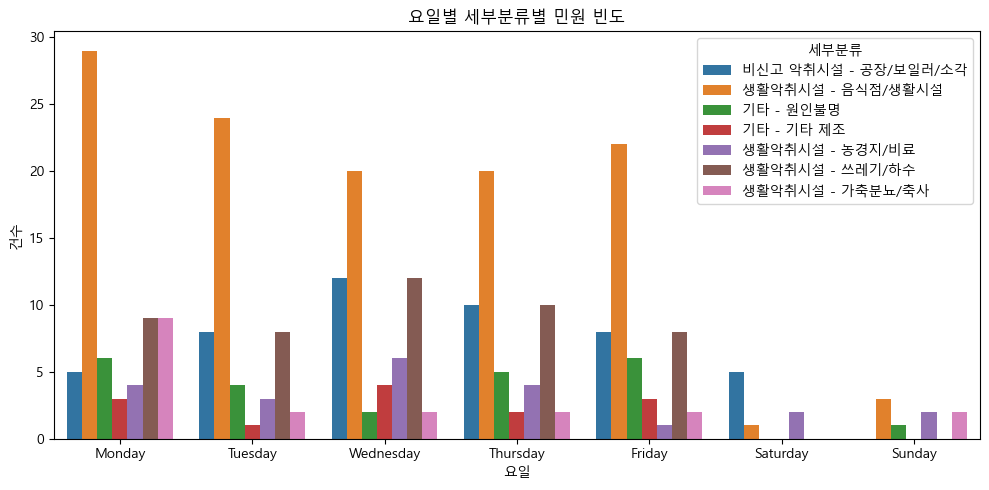

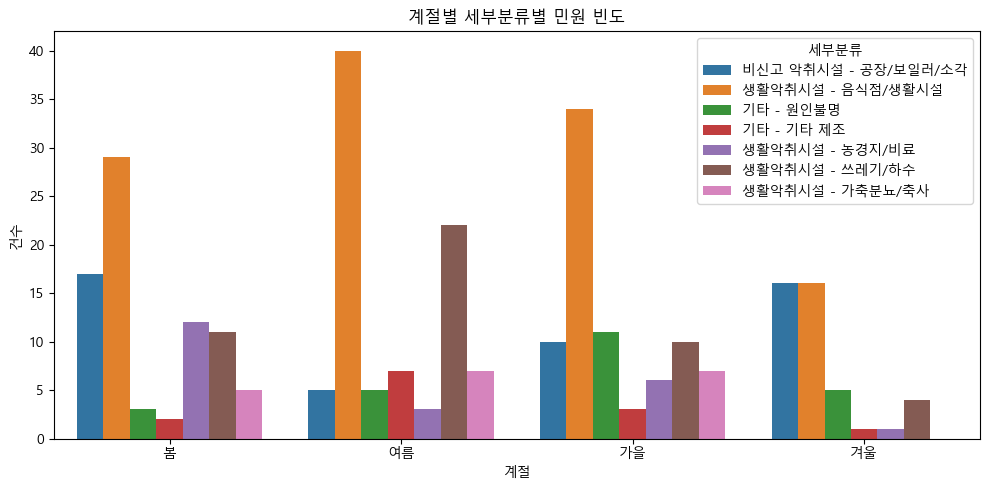

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

# 한글 폰트 설정 (시스템에 따라 조정 필요)
plt.rcParams["font.family"] = "Malgun Gothic"  # Windows
plt.rcParams["axes.unicode_minus"] = False

# 날짜를 datetime 형식으로 변환
test_df["날짜"] = pd.to_datetime(test_df["날짜"])

# 요일 컬럼 생성
test_df["요일"] = test_df["날짜"].dt.day_name()

# 계절 컬럼 생성
def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"

test_df["계절"] = test_df["날짜"].dt.month.apply(get_season)

# 요일 순서 지정
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
test_df["요일"] = pd.Categorical(test_df["요일"], categories=weekday_order, ordered=True)

# 날짜에서 월 정보 추출 (이미 datetime 형식인 경우)
test_df["월"] = pd.to_datetime(test_df["날짜"]).dt.month

# 세부분류별 월별 민원 건수 집계
monthly_counts = test_df.groupby(["월", "세부분류"]).size().unstack(fill_value=0)

# ✅ 월별 민원 빈도
plt.figure(figsize=(12, 6))
monthly_counts.plot(marker='o')
plt.title("세부분류별 월별 민원 발생 추이")
plt.xlabel("월")
plt.ylabel("민원 건수")
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="세부분류", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ✅ 요일별 민원 빈도
plt.figure(figsize=(10, 5))
sns.countplot(data=test_df, x="요일", hue="세부분류")
plt.title("요일별 세부분류별 민원 빈도")
plt.xlabel("요일")
plt.ylabel("건수")
plt.legend(title="세부분류")
plt.tight_layout()
plt.show()

# ✅ 계절별 민원 빈도
plt.figure(figsize=(10, 5))
sns.countplot(data=test_df, x="계절", hue="세부분류",
              order=["봄", "여름", "가을", "겨울"])
plt.title("계절별 세부분류별 민원 빈도")
plt.xlabel("계절")
plt.ylabel("건수")
plt.legend(title="세부분류")
plt.tight_layout()
plt.show()


### 월별민원발생추이 해석
음식점/생활시설 관련 민원이 가장 많고, 3-9월 동안 꾸준히 증가하며 8월에 정점을 기록함.<br>
쓰레기/하수 민원은 5-8월에 집중되며, 여름철 고온·습도의 영향이 뚜렷함.<br>
농경지/비료 민원은 봄(3-5월)과 가을(9월)에 높아지며, 농작업 시기와 연관됨.<br>
가축분뇨/축사는 6-10월 사이 소규모로 분산 발생하나, 여름철에 다소 증가.<br>
공장/보일러/소각 민원은 1월과 3월에 상대적으로 많이 발생하며, 난방·소각 활동 영향으로 추정됨.<br>
기타 제조/원인불명 민원은 전체적으로 건수가 적고 불규칙하게 발생함.<br>
전반적으로 6-9월 여름철에 모든 유형에서 민원 발생량이 증가하는 경향이 나타남.
이는 기온 상승 → 악취 확산 → 민원 증가로 이어지는 계절성 영향을 시사함.
민원 유형별 발생 시기 차이가 뚜렷하므로, 세부분류별로 맞춤형 대응 시기 설정이 필요함.
여름철에는 음식점, 하수, 축사 분야 중심의 집중 관리 전략이 요구됨.
봄·가을은 농업 악취 대응 중심의 계절별 현장 점검 체계가 적절함.
본 분석은 계절별 악취 민원 대응 및 예방 행정계획 수립의 기초자료로 활용 가능함.

### 요일별 민원빈도 종합해석
생활악취시설 - 음식점/생활시설은 주중(월-금)에 압도적으로 많이 발생하며, 월요일(최고 29건)에 정점을 찍음.<br>
해당 유형은 월요일부터 금요일까지 지속적으로 높게 유지되며, 주말(토-일)은 급감함.<br>
이는 주말 축적된 악취 민원이 월요일에 신고되는 패턴으로 해석 가능함.<br>
생활악취시설 - 쓰레기/하수 민원은 수요일에 가장 많고, 화-목까지 고르게 분포.<br>
비신고 악취시설(공장/보일러/소각)은 수요일과 목요일에 다소 증가하며, 주말에는 감소.<br>
농경지/비료, 가축분뇨/축사 민원은 건수 자체가 적고, 특정 요일에 집중되는 경향은 미약함.<br>
주말(토/일)에는 전반적인 민원 발생 건수가 급감함.
행정기관 운영일(평일)과 신고 가능 시간이 민원 제기에 영향을 준 것으로 보임.
요일별 민원 특성상 주초 집중 대응 체계 강화가 필요하며,
음식점 및 하수/쓰레기 관련 부서의 월요일 근무 배치 강화가 효과적일 수 있음.
특정 요일에 반복적으로 민원이 발생하는 유형에 대해서는 요일 기반 선제점검 전략 마련이 요구됨.
본 분석은 업무일 중심의 민원 대응 계획 수립에 유용한 기반 자료로 활용 가능함.

### 계절별 민원빈도 종합해석
생활악취시설 - 음식점/생활시설은 모든 계절에서 최다 발생, 특히 여름(40건)과 가을(34건)에 집중됨.<br>
여름철 민원은 고온 환경 속 음식물 부패 및 통풍 문제로 인해 악취가 심화된 것으로 추정됨.<br>
쓰레기/하수 관련 민원도 여름에 피크(22건)를 보이며, 습기와 폐기물 증가의 계절성 영향이 뚜렷함.<br>
농경지/비료 관련 민원은 봄에 가장 많이 발생(12건), 파종·비료 살포 시기와 연관.<br>
가축분뇨/축사 민원은 여름과 가을에 분포, 전반적으로 발생량은 낮으나 농촌 지역 이슈 가능성 있음.<br>
공장/소각 등 비신고 악취시설은 봄(17건)과 겨울(16건)에 집중되며, 계절 간 차이가 적은 편임.<br>
기타 제조/원인불명 민원은 모든 계절에서 적은 수치로 산발적으로 나타남.<br>
겨울철에는 전체적으로 민원 빈도가 감소하지만 음식점/공장 관련 민원은 여전히 유지됨.
계절별로 악취 원인과 유형이 다르므로, 맞춤형 대응 전략이 필수적이다.
특히 여름철 음식점·쓰레기 악취, 봄철 농작업 악취에 대한 사전 점검 및 집중 관리가 요구됨.
이러한 계절별 분석은 정책적 대응 우선순위 설정에 있어 매우 중요한 참고자료가 된다.

#### i) 세부분류와 축사, 산업단지, 페기물처리시설 관계

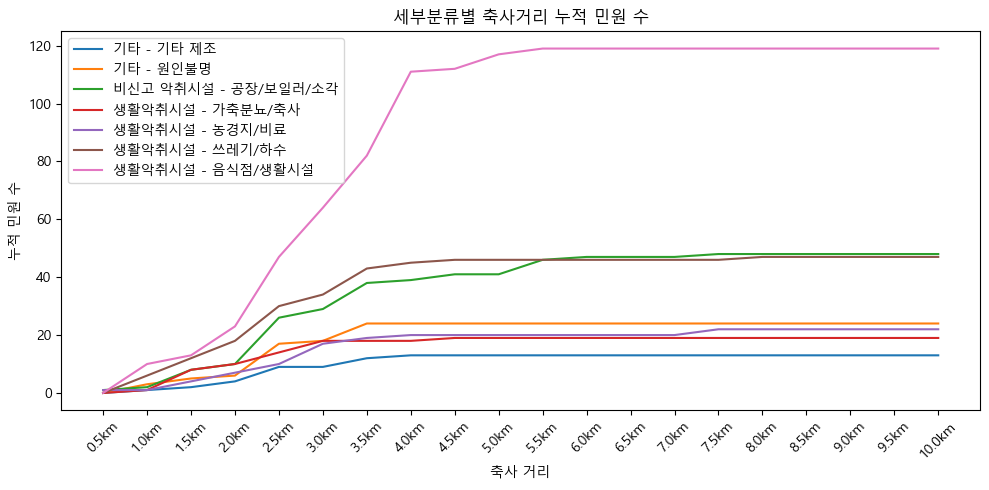

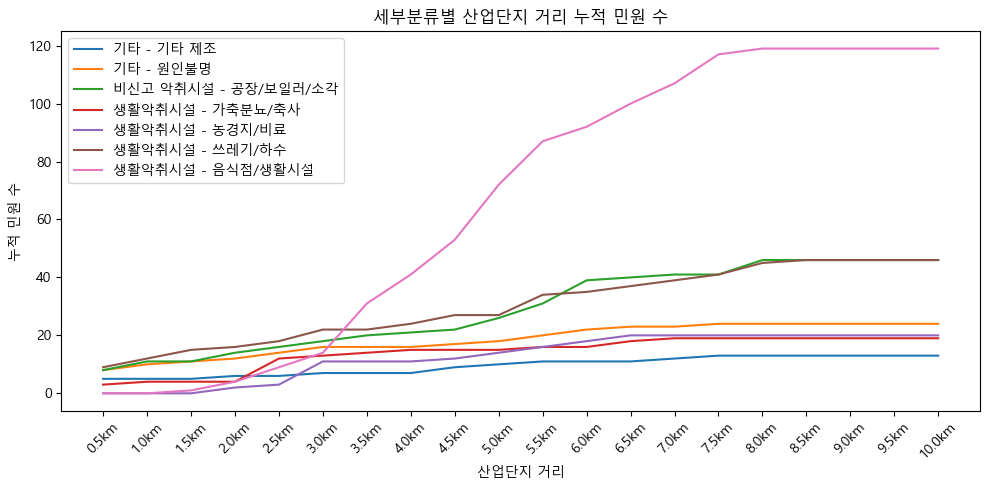

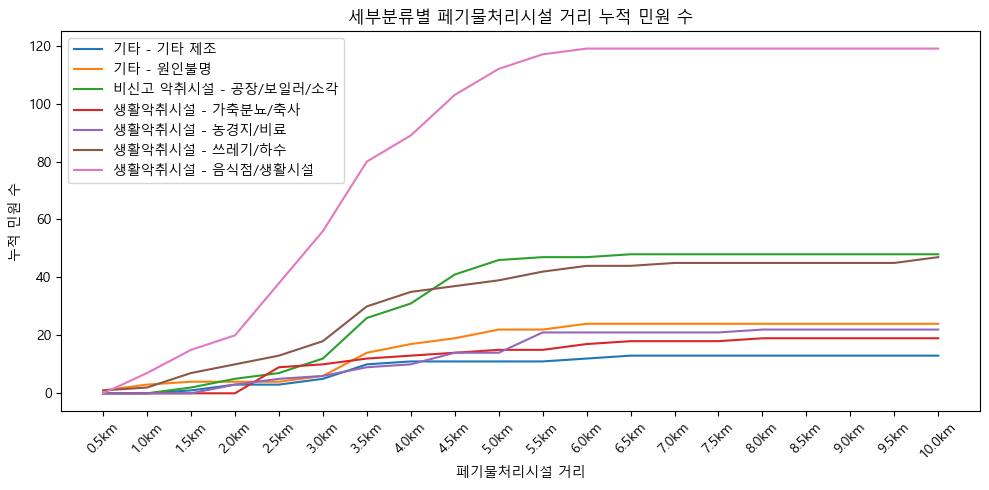

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from geopy.distance import geodesic

# --- 1. 데이터 불러오기 ---
pop_df = population_df

# --- 2. 거리 계산 함수 정의 ---
def get_nearest_distance(lat, lon, ref_df):
    if pd.isna(lat) or pd.isna(lon):
        return 0
    return ref_df.apply(
        lambda row: geodesic((lat, lon), (row["Latitude"], row["Longitude"])).meters,
        axis=1
    ).min()

# --- 3. 결측 제거 및 거리 계산 ---
test_df = test_df.dropna(subset=["Latitude", "Longitude"])

test_df["축사_거리(m)"] = test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], farm_df), axis=1
)

test_df["산업단지_거리(m)"] = test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], industry_df), axis=1
)
test_df["페기물처리시설_거리(m)"] = test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], trash_df), axis=1
)

# --- 4. 법정동 추출 및 인구 병합 ---
def extract_last_legal_dong(address):
    try:
        parts = address.split()
        return parts[-1] if len(parts) >= 3 else None
    except:
        return None

test_df["법정동"] = test_df["위치"].apply(extract_last_legal_dong)

# 열 이름 정리 후 병합
pop_df = pop_df[["읍면동명", "인구수(계)"]].dropna()
pop_df = pop_df.rename(columns={"읍면동명": "법정동", "인구수(계)": "총인구수"})
merged_df = test_df.merge(pop_df, on="법정동", how="left")

# --- 5. 누적 분석용 데이터 준비 ---
result_df = merged_df[["세부분류", "축사_거리(m)", "산업단지_거리(m)", "페기물처리시설_거리(m)"]].dropna()

# --- 6. 거리 구간 설정 및 누적합 계산 ---
distance_bins = np.arange(0, 10001, 500)
distance_labels = [f"{i/1000:.1f}km" for i in distance_bins[1:]]

farm_cumulative = (
    result_df.groupby("세부분류")["축사_거리(m)"]
    .apply(lambda s: np.histogram(s, bins=distance_bins)[0].cumsum())
)

industry_cumulative = (
    result_df.groupby("세부분류")["산업단지_거리(m)"]
    .apply(lambda s: np.histogram(s, bins=distance_bins)[0].cumsum())
)

trash_cumulative = (
    result_df.groupby("세부분류")["페기물처리시설_거리(m)"]
    .apply(lambda s: np.histogram(s, bins=distance_bins)[0].cumsum())
)
# --- 7. 시각화 ---

# 축사 거리 누적
plt.figure(figsize=(10, 5))
for cat in farm_cumulative.index:
    plt.plot(distance_labels, farm_cumulative.loc[cat], label=cat)
plt.xticks(rotation=45)
plt.title("세부분류별 축사거리 누적 민원 수")
plt.xlabel("축사 거리")
plt.ylabel("누적 민원 수")
plt.legend()
plt.tight_layout()
plt.show()

# 산업단지 거리 누적
plt.figure(figsize=(10, 5))
for cat in industry_cumulative.index:
    plt.plot(distance_labels, industry_cumulative.loc[cat], label=cat)
plt.xticks(rotation=45)
plt.title("세부분류별 산업단지 거리 누적 민원 수")
plt.xlabel("산업단지 거리")
plt.ylabel("누적 민원 수")
plt.legend()
plt.tight_layout()
plt.show()

# 페기물처리시설 거리 누적
plt.figure(figsize=(10, 5))
for cat in trash_cumulative.index:
    plt.plot(distance_labels, trash_cumulative.loc[cat], label=cat)
plt.xticks(rotation=45)
plt.title("세부분류별 페기물처리시설 거리 누적 민원 수")
plt.xlabel("페기물처리시설 거리")
plt.ylabel("누적 민원 수")
plt.legend()
plt.tight_layout()
plt.show()

### 종합 해석
음식점/생활시설 악취 민원은 모든 거리에서 지속적으로 많으며, 특정 시설 거리와 큰 연관은 없어 보입니다.
특히 폐기물처리시설로부터 2.5-4.5km 구간에서 급격히 민원이 증가하는 패턴을 보입니다.<br>
쓰레기/하수 민원은 폐기물처리시설 및 산업단지와 3-6km 이내 거리에서 급격히 증가합니다.
비신고 악취시설 - 공장/보일러/소각 민원도 산업단지에서 가까운 거리에서 민원 수가 크게 늘어납니다.<br>
농경지/비료 민원은 폐기물처리시설 및 축사와 관련 있으며, 3km 이내에서 집중 발생합니다.<br>
가축분뇨/축사 민원은 축사 인근 2-4km 거리에서 두드러지며 이후 증가 폭이 줄어듭니다.<br>
기타 제조, 원인불명 민원은 전체적으로 건수가 적고 거리 변화에 따른 영향도 뚜렷하지 않습니다.<br>
모든 세부분류에서 10km 이상 거리로부터는 민원이 거의 발생하지 않음을 확인할 수 있습니다.
시설 유형별로 민원 발생 반경이 다르며, 음식점 악취는 지역 밀도와 관련이 깊은 반면,
공장·축사·쓰레기 악취는 인근 특정 시설과의 거리 영향이 명확하게 나타납니다.
이를 통해 중점 관리 반경(예: 3-5km) 설정이 가능하며, 시설 유형별 대응 전략 수립에 활용할 수 있습니다.

#### j) 해결유무와 기상별 상관관계

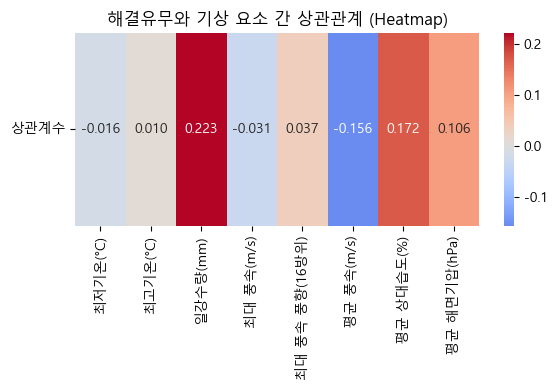

In [81]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 파일 불러오기

# 해결유무 구분 함수 정의
def classify_resolution(text):
    if isinstance(text, str):
        text_lower = text.lower()
        if any(keyword in text_lower for keyword in ['조치 완료', '설치 완료', '연장토록 조치', '공사 완료', '민원 종결', '필터 설치', '해결']):
            return 1
        elif any(keyword in text_lower for keyword in ['검토하겠다는 답변', '요청함', '예정', '어려움', '힘들', '불가', '없었음']):
            return 0
    return None

# 해결유무 열 추가
test_df["해결유무"] = test_df["민원 처리 결과"].apply(classify_resolution)

# 기상 요소 열만 추출
weather_cols = [col for col in test_df.columns if any(keyword in col for keyword in ['기온', '강수', '풍속', '습도', '기압'])]
weather_cols.append("해결유무")

# 결측치 제거
df_corr = test_df[weather_cols].dropna()

# 상관관계 계산
correlation_df = df_corr.corr(numeric_only=True)["해결유무"].drop("해결유무").to_frame(name="상관계수")

# 히트맵 그리기
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_df.T, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("해결유무와 기상 요소 간 상관관계 (Heatmap)")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### 종합해석
일강수량(상관계수 +0.223)이 가장 높은 양의 상관관계를 보여, 비가 많이 온 날 민원이 더 잘 해결되는 경향이 있습니다.
평균 상대습도(+0.172)도 민원 해결과 다소 관련 있으며, 습한 날일수록 해결 가능성이 높습니다.
평균 풍속은 -0.156로 음의 상관관계를 보여, 바람이 강할수록 민원 해결이 어려울 수 있습니다.
기온(최저·최고), 풍속 방향, 최대 풍속 등은 상관성이 거의 없음을 나타냅니다.
전반적으로 날씨보다는 풍속과 강수량이 해결 여부에 더 큰 영향을 미치는 변수입니다.

#### k) 해결유무와 시간별 관계

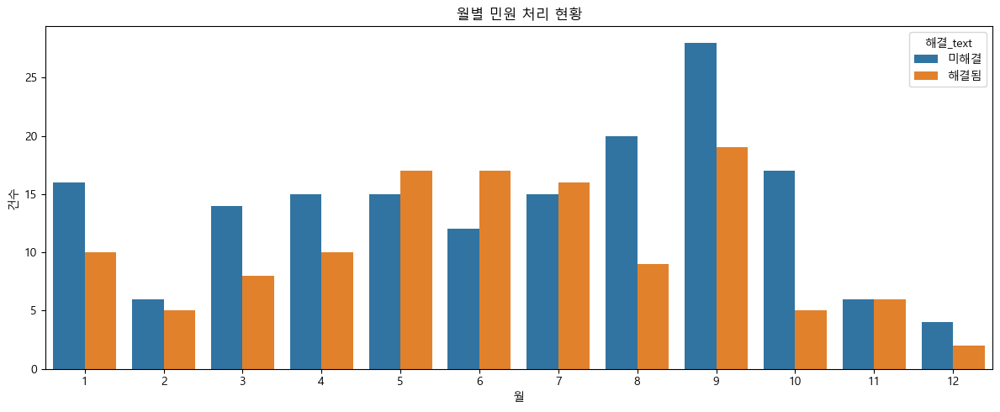

C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\2851663459.py:44: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  weekday = complaint_df.groupby(["요일", "해결_text"]).size().reset_index(name="건수")


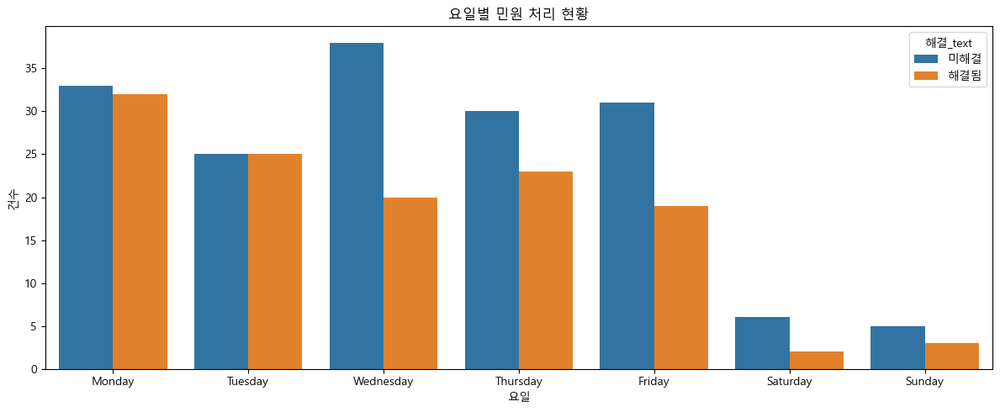

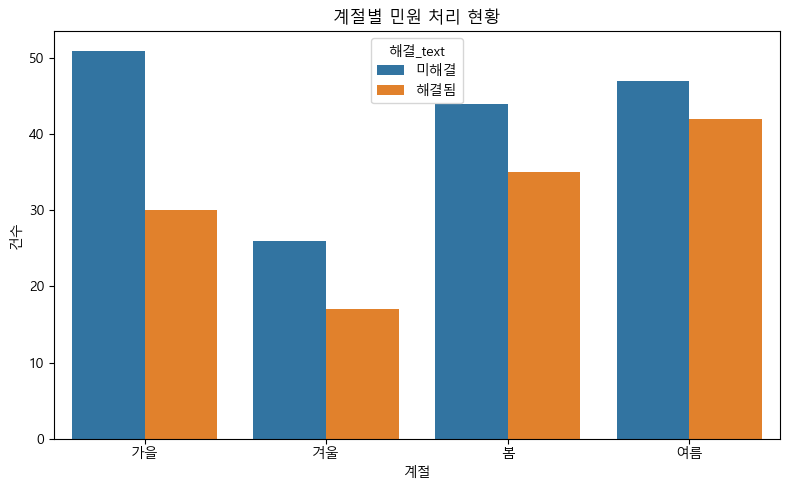

In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 불러오기
df = complaint_df

# 2. '해결유무' 정제 및 숫자/텍스트 열 생성
complaint_df = complaint_df[complaint_df["해결유무"].isin(["해결", "미해결"])].copy()
complaint_df["해결유무_수"] = complaint_df["해결유무"].map({"해결": 0.0, "미해결": 1.0})
complaint_df["해결_text"] = complaint_df["해결유무_수"].map({0.0: "해결됨", 1.0: "미해결"})

# 3. 날짜 관련 파생변수
complaint_df["민원 발생 일시"] = pd.to_datetime(complaint_df["민원 발생 일시"])
complaint_df["월"] = complaint_df["민원 발생 일시"].dt.month
complaint_df["요일"] = complaint_df["민원 발생 일시"].dt.day_name()

# 4. 계절 구하기 함수
def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"

complaint_df["계절"] = complaint_df["월"].apply(get_season)
complaint_df["요일"] = pd.Categorical(complaint_df["요일"], categories=[
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
], ordered=True)

# 5. 시각화 설정 (한글 폰트는 환경에 맞게 수정)
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 환경
# plt.rcParams['font.family'] = 'AppleGothic'  # Mac
plt.rcParams['axes.unicode_minus'] = False

# 6. 월별 그래프
monthly = complaint_df.groupby(["월", "해결_text"]).size().reset_index(name="건수")
plt.figure(figsize=(12, 5))
sns.barplot(data=monthly, x="월", y="건수", hue="해결_text")
plt.title("월별 민원 처리 현황")
plt.tight_layout()
plt.show()

# 7. 요일별 그래프
weekday = complaint_df.groupby(["요일", "해결_text"]).size().reset_index(name="건수")
plt.figure(figsize=(12, 5))
sns.barplot(data=weekday, x="요일", y="건수", hue="해결_text")
plt.title("요일별 민원 처리 현황")
plt.tight_layout()
plt.show()

# 8. 계절별 그래프
season = complaint_df.groupby(["계절", "해결_text"]).size().reset_index(name="건수")
plt.figure(figsize=(8, 5))
sns.barplot(data=season, x="계절", y="건수", hue="해결_text")
plt.title("계절별 민원 처리 현황")
plt.tight_layout()
plt.show()


### 종합 해석
봄과 여름은 민원 발생이 많고 해결 비율도 높습니다.
가을은 미해결 민원이 가장 많아, 처리율이 낮은 시기입니다.
겨울은 전체 민원 수가 적고, 해결률도 낮은 편입니다.
수요일에 미해결 민원이 집중되며, 처리 성과가 떨어집니다.
월요일과 화요일은 민원도 많지만 해결 비율이 높습니다.
9월은 민원이 가장 많고, 미해결 비중도 높은 문제 시기입니다.
5~7월은 비교적 처리율이 양호하여 대응 효과가 좋습니다.
주말(토·일)은 민원이 적고, 처리도 거의 이루어지지 않습니다.

#### l) 해결유무와 세부분류 관계

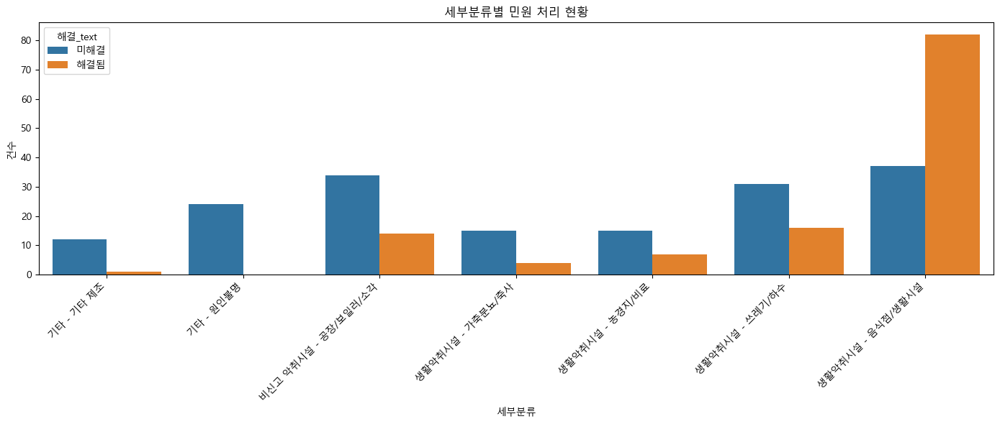

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. 해결유무 컬럼 정제
complaint_df = complaint_df[complaint_df["해결유무"].isin(["해결", "미해결"])].copy()
complaint_df["해결유무_수"] = complaint_df["해결유무"].map({"해결": 0.0, "미해결": 1.0})
complaint_df["해결_text"] = complaint_df["해결유무_수"].map({0.0: "해결됨", 1.0: "미해결"})

# 3. 세부분류별 해결유무 건수 집계
category_resolution = complaint_df.groupby(["세부분류", "해결_text"]).size().reset_index(name="건수")

# 4. 시각화 설정 (폰트 환경에 맞게 설정)
plt.rcParams['font.family'] = 'Malgun Gothic'  # Windows
# plt.rcParams['font.family'] = 'AppleGothic'  # Mac
plt.rcParams['axes.unicode_minus'] = False

# 5. 그래프 그리기
plt.figure(figsize=(14, 6))
sns.barplot(data=category_resolution, x="세부분류", y="건수", hue="해결_text")
plt.title("세부분류별 민원 처리 현황")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 해석
'생활악취시설 - 음식점/생활시설'은 전체 민원 수가 가장 많고, 해결된 비율도 가장 높습니다.
'비신고 악취시설 - 공장/보일러/소각'과 '생활악취시설 - 쓰레기/하수'는 미해결 민원이 많아 처리율이 낮습니다.
'기타 - 원인불명'은 전부 미해결로, 원인 파악조차 어려운 경우가 많습니다.
기타 제조, 가축분뇨/축사, 농경지/비료 관련 민원도 해결 비율이 낮은 편입니다.
악취 유형 중 가시성과 명확한 원인을 가진 음식점 관련 민원은 비교적 대응이 잘 이루어집니다.
반면 공장, 쓰레기, 축사, 원인불명은 지속적으로 대응이 미흡한 경향을 보입니다.
유형별 해결 편차가 커, 취약 분야에 대한 집중 대응과 제도적 보완이 필요합니다.

#### m) 해결유무와 축사, 산업단지, 페기물처리시설 거리

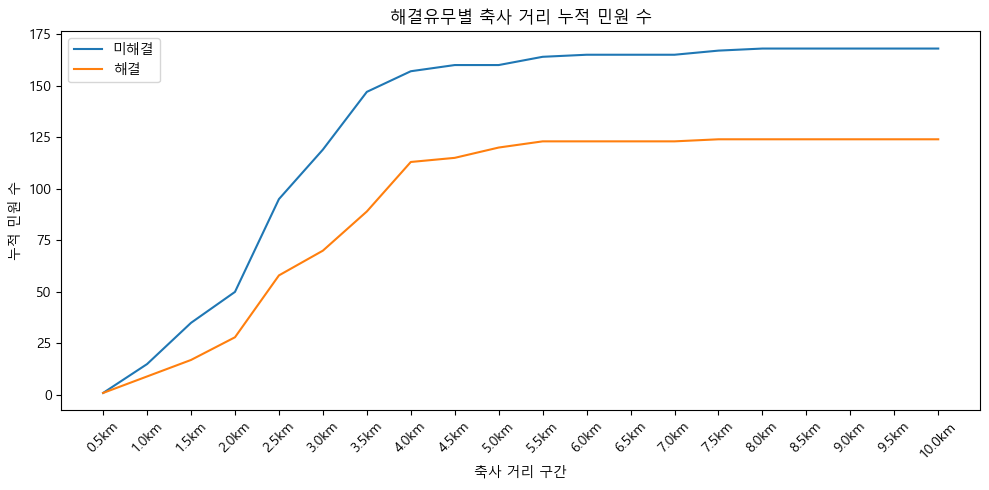

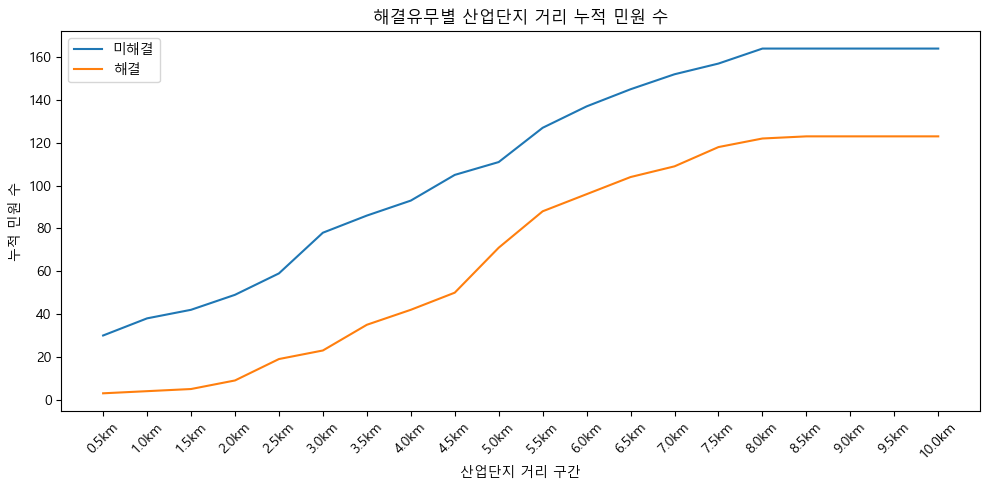

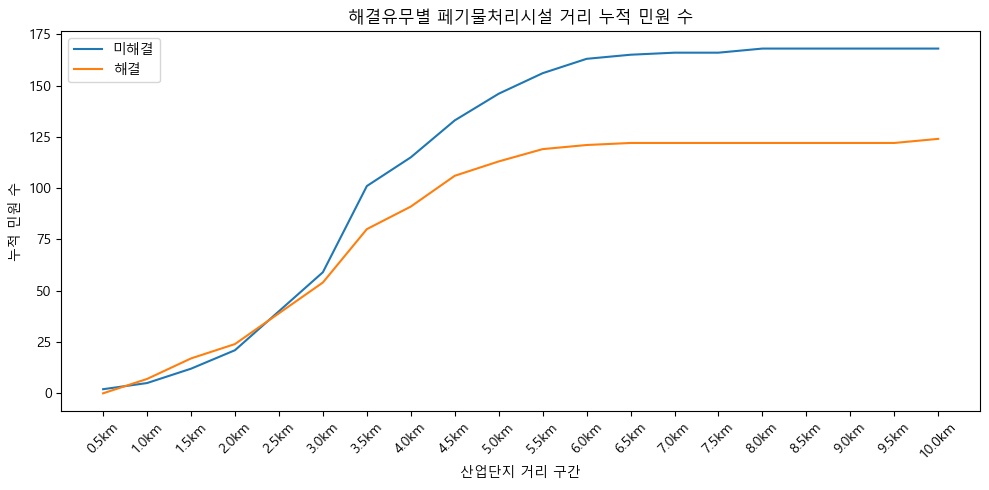

In [90]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 거리 구간 설정 (0 ~ 10km, 500m 간격)
distance_bins = np.arange(0, 10001, 500)
distance_labels = [f"{i/1000:.1f}km" for i in distance_bins[1:]]

# 2. '해결_text' 컬럼 생성
test_df["해결_text"] = test_df["해결"].map({0.0: "해결", 1.0: "미해결"})

# 3. 축사 거리 누적 민원 수 계산 (해결유무별)
farm_cumulative = (
    test_df.groupby("해결_text")["축사_거리(m)"]
    .apply(lambda s: np.histogram(s, bins=distance_bins)[0].cumsum())
)

# 4. 산업단지 거리 누적 민원 수 계산
industry_cumulative = (
    test_df.groupby("해결_text")["산업단지_거리(m)"]
    .apply(lambda s: np.histogram(s, bins=distance_bins)[0].cumsum())
)

trash_cumulative = (
    test_df.groupby("해결_text")["페기물처리시설_거리(m)"]
    .apply(lambda s: np.histogram(s, bins=distance_bins)[0].cumsum())
)

# 5. 시각화: 축사 거리 누적 민원 수
plt.figure(figsize=(10, 5))
for label in farm_cumulative.index:
    plt.plot(distance_labels, farm_cumulative.loc[label], label=label)
plt.title("해결유무별 축사 거리 누적 민원 수")
plt.xlabel("축사 거리 구간")
plt.ylabel("누적 민원 수")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# 6. 시각화: 산업단지 거리 누적 민원 수
plt.figure(figsize=(10, 5))
for label in industry_cumulative.index:
    plt.plot(distance_labels, industry_cumulative.loc[label], label=label)
plt.title("해결유무별 산업단지 거리 누적 민원 수")
plt.xlabel("산업단지 거리 구간")
plt.ylabel("누적 민원 수")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# 7. 시각화: 페기물처리시설 거리 누적 민원 수
plt.figure(figsize=(10, 5))
for label in trash_cumulative.index:
    plt.plot(distance_labels, trash_cumulative.loc[label], label=label)
plt.title("해결유무별 페기물처리시설 거리 누적 민원 수")
plt.xlabel("산업단지 거리 구간")
plt.ylabel("누적 민원 수")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### 종합해석
폐기물처리시설에서 가까울수록 민원 수가 빠르게 증가하며, 3.5km까지 급증합니다.
폐기물처리시설과 3~6km 거리에서 미해결 민원이 해결보다 훨씬 많습니다.
이후 거리 구간에서는 민원 증가가 둔화되며, 해결률도 정체됩니다.
산업단지 거리에서도 유사한 경향이 나타나며, 5km까지 미해결 민원이 급증합니다.
5km 이후 해결된 민원은 거의 증가하지 않지만, 미해결 민원은 계속 누적됩니다.
축사 거리에서도 3.5km까지 미해결 민원이 급증하고, 해결 민원과 큰 차이를 보입니다.
가까운 거리일수록 민원은 더 많이 접수되지만, 해결보다는 미해결이 많아 대응 부족을 시사합니다.
환경시설 근접 지역에서의 민원 처리율 제고가 주요 과제로 보입니다.

#### n) 민원여부와 기상의 상관관계는 c를 확인

#### o) 민원여부와 월, 계절, 요일의 상관관계는 b를 확인

#### p) 민원여부와 산업단지, 축사, 페기물처리시설의 상관관계는 a를 확인

# 04 모델링

## a) 해결유무 예측

📊 Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.59      0.55        22
           1       0.74      0.68      0.70        37

    accuracy                           0.64        59
   macro avg       0.63      0.63      0.63        59
weighted avg       0.66      0.64      0.65        59


🧩 Confusion Matrix:
[[13  9]
 [12 25]]


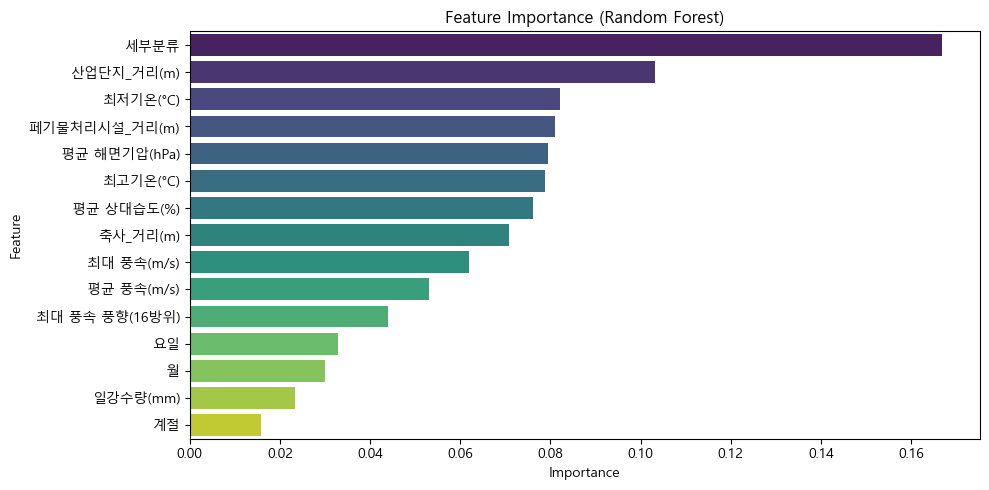

In [97]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# 1. 데이터 불러오기
df = test_df

# 2. 해결 컬럼 이름 정리
df = df.rename(columns={"해결=0, 미해결=1": "해결"})
df = df[df["해결"].isin([0.0, 1.0])].copy()

# 3. 날짜 파생변수 처리
df["날짜"] = pd.to_datetime(df["날짜"])
df["월"] = df["날짜"].dt.month
df["요일"] = df["날짜"].dt.day_name()

def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"
df["계절"] = df["월"].apply(get_season)
df["요일"] = pd.Categorical(df["요일"], categories=[
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
], ordered=True)

# 4. 사용 feature 선택
features = ["축사_거리(m)", "산업단지_거리(m)","페기물처리시설_거리(m)",
    "세부분류",
    "월", "요일", "계절",
    "평균 풍속(m/s)", "일강수량(mm)", "최고기온(°C)", "최저기온(°C)", "최대 풍속(m/s)", "평균 해면기압(hPa)", "평균 상대습도(%)", "최대 풍속 풍향(16방위)"
]
model_df = df[features + ["해결"]].dropna().reset_index(drop=True)

# 5. 범주형 변수 인코딩
categorical_cols = ["세부분류", "요일", "계절"]
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    model_df[col] = le.fit_transform(model_df[col])
    label_encoders[col] = le

# 6. train/test split
X = model_df.drop(columns="해결")
y = model_df["해결"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. 모델 학습
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 8. 평가
print("📊 Classification Report:")
print(classification_report(y_test, y_pred))
print("\n🧩 Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 9. 중요 변수 시각화
importances = clf.feature_importances_
feature_names = X.columns
feat_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=feat_imp_df,
    x="Importance", y="Feature",
    hue="Feature", dodge=False, legend=False, palette="viridis"
)
plt.title("Feature Importance (Random Forest)")  # 이모지 제거
plt.tight_layout()
plt.show()


### 종합해석
전체 **정확도는 64%로 준수한 수준의 예측 성능을 보여줍니다.
Recall 0.70, Precision 0.74로 ‘미해결(1)’ 민원을 비교적 잘 예측하고 있습니다.
혼동행렬에서 미해결을 해결로 잘못 예측한 건수는 9건, 반대는 12건입니다.
‘세부분류’가 가장 중요한 변수로, 민원의 유형이 해결 여부에 가장 큰 영향을 미칩니다.
산업단지 거리와 폐기물처리시설 거리도 중요도 상위에 포함되며, 공간적 요인도 큰 영향을 미칩니다.
최저기온, 해면기압, 최고기온 등 기상 변수들도 민원 해결과 연관이 있습니다.
요일·월·계절은 중요도가 낮아, 시간적 요인보다는 민원 성격과 입지 조건이 중요함을 시사합니다.
전반적으로 유형 + 거리 + 기상 조건 조합이 해결 예측에 핵심이라는 점이 드러납니다.

## b) 민원유무예측

In [100]:
# import numpy as np
# import pandas as pd
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import classification_report
# from imblearn.over_sampling import SMOTE
# import matplotlib.pyplot as plt
# import seaborn as sns

# T_test_df["축사_거리(m)"] = T_test_df.apply(
#     lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], farm_df), axis=1
# )

# T_test_df["산업단지_거리(m)"] = T_test_df.apply(
#     lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], industry_df), axis=1
# )
# T_test_df["페기물처리시설_거리(m)"] = T_test_df.apply(
#     lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], trash_df), axis=1
# )

# # 1. 데이터 복사 및 전처리
# df = T_test_df.copy()

# # 3. 특성과 라벨 설정
# features = ["축사_거리(m)", "산업단지_거리(m)", "페기물처리시설_거리(m)", "세부분류_코드"]

# X = df[features]
# y = df['민원발생여부']  # 0: 미발생, 1: 발생

# # 4. 학습/테스트 분할
# X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# # 5. SMOTE 오버샘플링
# smote = SMOTE(random_state=42)
# X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# # 6. RandomForest 모델 학습
# modelx = RandomForestClassifier(random_state=42)
# modelx.fit(X_resampled, y_resampled)

# # 7. 예측 및 평가
# y_pred = modelx.predict(X_test)
# print(classification_report(y_test, y_pred))

# # 8. 변수 중요도 시각화
# importances = modelx.feature_importances_
# feat_imp_df = pd.DataFrame({
#     "Feature": X.columns,
#     "Importance": importances
# }).sort_values(by="Importance", ascending=False)

# plt.figure(figsize=(10, 5))
# sns.barplot(
#     data=feat_imp_df,
#     x="Importance", y="Feature",
#     hue="Feature", dodge=False, legend=False, palette="viridis"
# )
# plt.title("Feature Importance (Random Forest)")  # 이모지 제거
# plt.tight_layout()
# plt.show()



### 종합해석
처음에는 모든 독립변수를 넣어서 만들려고 했으나 과적합문제가 발생. 
원인을 찾아보니 민원이 없는 모든 데이터의 거리가 0이고 세부분류도 나오지 않기에 둘을 모델에서 제외함.

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       222
           1       0.58      0.41      0.48        73

    accuracy                           0.78       295
   macro avg       0.70      0.66      0.67       295
weighted avg       0.76      0.78      0.77       295



C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\3963947790.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis")


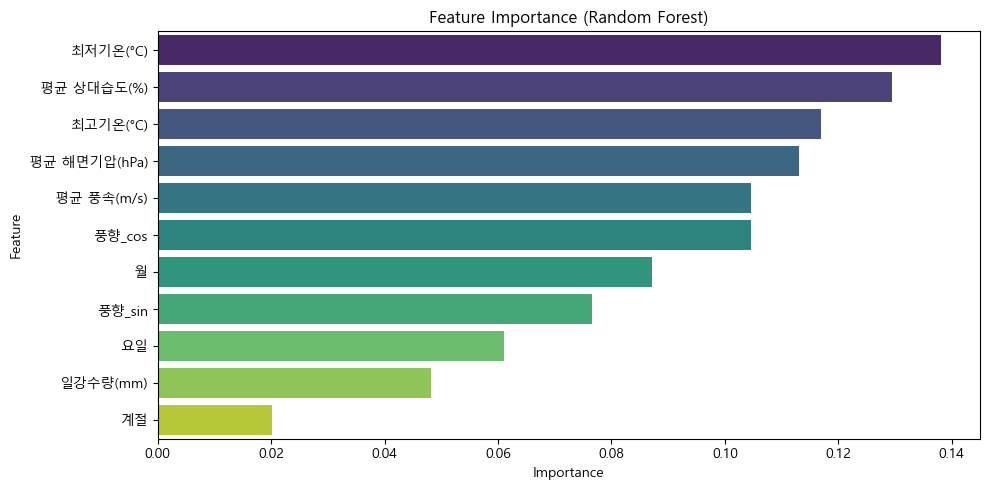

In [102]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 준비
df = T_test_df.copy()

# 풍향 → 라디안 → sin/cos
df = df.dropna(subset=["최대 풍속 풍향(16방위)"])
df["풍향_rad"] = np.deg2rad(df["최대 풍속 풍향(16방위)"])
df["풍향_sin"] = np.sin(df["풍향_rad"])
df["풍향_cos"] = np.cos(df["풍향_rad"])

# 날짜 파생변수 처리
df["날짜"] = pd.to_datetime(df["날짜"])
df["월"] = df["날짜"].dt.month
df["요일"] = df["날짜"].dt.day_name()

def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"
df["계절"] = df["월"].apply(get_season)

# Label Encoding (문자형으로 강제 후 인코딩)
for col in ["요일", "계절"]:
    df[col] = df[col].astype(str)
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

# 2. 특성과 라벨 정의
features = [
    '최저기온(°C)', '최고기온(°C)', '일강수량(mm)',
    '평균 풍속(m/s)', '평균 상대습도(%)', '평균 해면기압(hPa)',
    '풍향_sin', '풍향_cos',
    "월", "요일", "계절"
]
X = df[features]
y = df["민원발생여부"]

# 3. Train/Test 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# 4. SMOTE로 오버샘플링
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# 5. Random Forest 학습
model02 = RandomForestClassifier(random_state=42)
model02.fit(X_resampled, y_resampled)

# 6. 예측 및 평가
y_pred = model02.predict(X_test)
print(classification_report(y_test, y_pred))

# 7. 변수 중요도 시각화
importances = model02.feature_importances_
feat_imp_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis")
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()


### 종합분석
**정확도는 78%**로 전체 성능은 양호합니다.
그러나 민원 있음(1) 클래스의 Recall이 0.44로 낮아, 발생 민원을 놓치는 경우가 많습니다.
최저기온, 최고기온, 상대습도, 해면기압 등 기상 요소들이 주요 예측 변수로 작용합니다.
풍속과 풍향 변수도 민원 예측에 유의미한 기여를 합니다.
일강수량은 예측 기여도가 낮은 편입니다.
전반적으로 기상 조건만으로 민원 예측이 가능하지만, 민원 발생을 잘 포착하진 못합니다.
민원 유형, 위치 정보 등 추가 변수가 필요합니다.

### c) 세부분류별 민원빈도 예측

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         3
           2       0.12      0.17      0.14         6
           3       0.50      0.42      0.45        12
           4       0.36      0.80      0.50         5
           5       0.20      0.17      0.18        12
           6       0.62      0.53      0.57        30
           7       0.00      0.00      0.00         5

    accuracy                           0.38        73
   macro avg       0.26      0.30      0.26        73
weighted avg       0.40      0.38      0.39        73



C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\3493527334.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis")


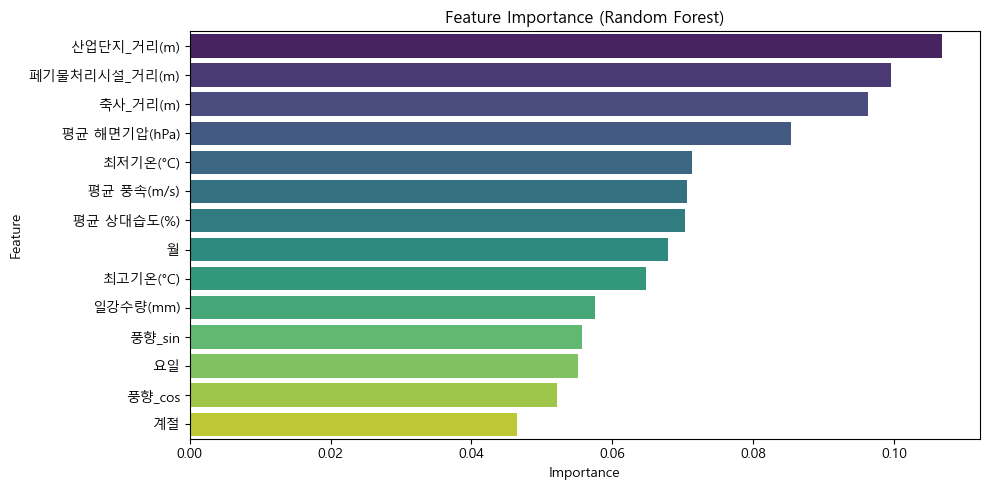

In [105]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import pandas as pd

test_df["축사_거리(m)"] = test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], farm_df), axis=1
)

test_df["산업단지_거리(m)"] = test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], industry_df), axis=1
)
test_df["페기물처리시설_거리(m)"] = test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], trash_df), axis=1
)

# 풍향 → 라디안 → sin/cos
test_df = test_df.dropna(subset=["최대 풍속 풍향(16방위)"])
test_df["풍향_rad"] = np.deg2rad(test_df["최대 풍속 풍향(16방위)"])
test_df["풍향_sin"] = np.sin(test_df["풍향_rad"])
test_df["풍향_cos"] = np.cos(test_df["풍향_rad"])

# 날짜 파생변수 처리
test_df["날짜"] = pd.to_datetime(test_df["날짜"])
test_df["월"] = test_df["날짜"].dt.month
test_df["요일"] = test_df["날짜"].dt.day_name()

def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"
test_df["계절"] = test_df["월"].apply(get_season)

# Label Encoding (문자형으로 강제 후 인코딩)
for col in ["요일", "계절"]:
    test_df[col] = test_df[col].astype(str)
    le = LabelEncoder()
    test_df[col] = le.fit_transform(test_df[col])


# 1. 데이터 구성
features = [
    "축사_거리(m)", "산업단지_거리(m)", "페기물처리시설_거리(m)",
    "최고기온(°C)", "최저기온(°C)", "평균 풍속(m/s)", "풍향_sin", "풍향_cos",
    "평균 해면기압(hPa)", "평균 상대습도(%)", "일강수량(mm)",
    "월", "요일", "계절"
]

X = test_df[features].fillna(0)
y = test_df["세부분류_코드"].astype(int)

# 2. Train/Test 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

# 3. 파이프라인 (표준화 + SMOTE + RandomForest)
model03 = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('clf', RandomForestClassifier(random_state=42))
])

# 4. 모델 학습
model03.fit(X_train, y_train)

# 5. 예측 및 평가
y_pred = model03.predict(X_test)
print(classification_report(y_test, y_pred))

# 6. 변수 중요도 추출
importances = model03.named_steps['clf'].feature_importances_

# 7. 변수 중요도 시각화
feat_imp_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis")
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()


### 종합분석
전체 정확도는 38%로 낮으며, 분류 성능이 전반적으로 저조함.
Class 1, 6, 7은 예측을 전혀 못함 (F1=0.00).
Class 5는 비교적 잘 예측됨 (F1=0.67).
데이터 불균형이 심각하여 성능 왜곡 발생.
가장 중요한 변수는 산업단지_거리, 폐기물처리시설_거리, 축사_거리.
기온, 풍속 등 일부 기상 변수도 중간 중요도.
계절, 요일, 풍향 등 시간/방향 변수는 영향도 낮음.
class_weight='balanced', SMOTE+Tomek 같은 기법 추천.
세부분류별 민원 특성을 반영한 텍스트 기반 정보(NLP) 활용도 고려.
소수 클래스 예측력 개선 위한 하이퍼파라미터 튜닝과 데이터 보강 필요.

### 악취 민원 맵

#### a) 풍향에 따른 악취 확산

In [109]:
import pandas as pd
import numpy as np
import folium
from folium.plugins import HeatMapWithTime, MarkerCluster
from datetime import datetime

new_test_df = test_df.copy()
# 1. 민원 + 날씨 데이터 전처리
new_test_df = new_test_df[["Latitude", "Longitude", "날짜", "위치", "세부분류", "민원 내용", "민원 처리 결과", "해결"]].dropna()

new_test_df["날짜"] = pd.to_datetime(new_test_df["날짜"])
unique_dates = sorted(new_test_df["날짜"].dt.date.unique())

# 2. 날씨 데이터 날짜 처리
weather_df["날짜"] = pd.to_datetime(weather_df["일시"]).dt.date

# 3. 시설 데이터 통합
def prep_facility(df, label):
    return df[["Latitude", "Longitude", "면적(제곱미터)"]].assign(구분=label).dropna()

industry_df_ready = prep_facility(industry_df, "산업단지")
farm_df_ready = prep_facility(farm_df, "축사")
trash_df_ready = prep_facility(trash_df, "폐기물처리시설")

facility_df = pd.concat([industry_df_ready, farm_df_ready, trash_df_ready], ignore_index=True)
facility_df = facility_df.rename(columns={"면적(제곱미터)": "면적"})

# 4. 지도 초기화
center = [facility_df["Latitude"].mean(), facility_df["Longitude"].mean()]
m = folium.Map(location=center, zoom_start=12)

# 5. 히트맵 시퀀스 생성
heatmap_sequence = []
for date in unique_dates:
    daily_weather = weather_df[weather_df["날짜"] == date]
    if daily_weather.empty:
        continue

    wind_speed = daily_weather["최대 풍속(m/s)"].mean()
    wind_dir_deg = daily_weather["최대 풍속 풍향(16방위)"].mean()
    if np.isnan(wind_speed) or np.isnan(wind_dir_deg):
        continue

    wind_dir_rad = np.deg2rad(wind_dir_deg)
    points = []
    for _, row in facility_df.iterrows():
        lat, lon, area = row["Latitude"], row["Longitude"], row["면적"]
        if pd.isna(lat) or pd.isna(lon) or pd.isna(area) or area <= 0:
            continue

        area_factor = np.sqrt(area) / 300
        steps = int(min(15, wind_speed * 2))
        for i in range(steps):
            offset = area_factor * (0.001 + i * 0.0005)
            offset_lat = lat + offset * np.sin(wind_dir_rad)
            offset_lon = lon + offset * np.cos(wind_dir_rad)
            if np.isnan(offset_lat) or np.isnan(offset_lon):
                continue
            weight = 0.7 * (1.0 - (i / steps) * 0.6)
            points.append([offset_lat, offset_lon, weight])
    heatmap_sequence.append(points)

if heatmap_sequence:
    HeatMapWithTime(
        data=heatmap_sequence,
        index=[str(d) for d in unique_dates[:len(heatmap_sequence)]],
        auto_play=True,
        radius=25,
        max_opacity=0.75
    ).add_to(m)

# 6. 시설 마커 추가
for _, row in facility_df.iterrows():
    location = [row["Latitude"], row["Longitude"]]
    label = row["구분"]
    color = "green" if label == "축사" else "purple" if label == "산업단지" else "gray"
    icon = folium.Icon(color=color, icon="paw" if label=="축사" else "industry" if label=="산업단지" else "trash", prefix="fa")
    folium.Marker(location, tooltip=label, icon=icon).add_to(m)

# 7. 민원 마커 클러스터 추가
def get_color2(row):
    if '공장' in row['세부분류'] or '소각' in row['세부분류'] or '보일러' in row['세부분류']:
        return 'red'
    elif '음식점' in row['세부분류'] or '생활시설' in row['세부분류']:
        return 'orange'
    elif '농경지' in row['세부분류'] or '비료' in row['세부분류']:
        return 'green'
    elif '쓰레기' in row['세부분류'] or '하수' in row['세부분류']:
        return 'blue'
    elif '제조' in row['세부분류']:
        return 'purple'
    elif '축사' in row['세부분류'] or '가축분뇨' in row['세부분류']:
        return 'lightgray'
    elif '기타' in row['세부분류'] or '원인불명' in row['세부분류']:
        return 'beige'
    else:
        return 'black'

def get_icon_shape(value):
    return 'ok-sign' if value == 0 else 'remove-sign'

cluster = MarkerCluster(name="민원 마커").add_to(m)

for _, row in new_test_df.iterrows():
    popup_text = (
        f"<b>날짜:</b> {row['날짜'].date()}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
        f"<b>세부분류:</b> {row['세부분류']}<br>"
        f"<b>민원내용:</b> {row['민원 내용']}<br>"
        f"<b>처리결과:</b> {row['민원 처리 결과']}<br>"
        f"<b>해결여부:</b> {'해결' if row['해결'] == 0 else '미해결'}"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color=get_color2(row), icon=get_icon_shape(row['해결']), prefix='glyphicon')
    ).add_to(cluster)

# 8. 범례 추가
legend_html = """
<div style="
position: fixed; 
bottom: 50px; left: 30px; width: 260px; 
z-index:9999; font-size:14px;
background-color:white; padding:10px; border:2px solid gray;
">
<b>🟢 민원 분류별 색상</b><br>
🔴 공장/소각/보일러<br>
🟠 음식점/생활시설<br>
🟢 농경지/비료<br>
⚫ 가축분뇨/축사<br>
🔵 쓰레기/하수<br>
🟣 기타 제조<br>
🟤 기타/불명<br><br>
<b>✔️ 아이콘</b><br>
✔️ 민원 해결<br>
❌ 민원 미해결<br><br>
<b>기타 마커</b><br>
<i style='color:blue;' class='fa fa-paw'></i> 축사 위치<br>
<i style='color:purple;' class='fa fa-industry'></i> 산업단지 위치<br>
<i style='color:gray;' class='fa fa-trash'></i> 폐기물처리시설 위치<br>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# 9. 저장
output_path = "/mnt/data/시설_면적비례_히트맵_최종_통합.html"
m.save(output_path)
m

#### b) 인구밀도 축사 산업단지와 민원의 해결유무를 나타낸 악취맵 

In [111]:
import shapefile
import folium
import pandas as pd
from pyproj import Transformer
from branca.element import Template, MacroElement
from folium.plugins import MarkerCluster


# 1. 좌표계 변환기
transformer = Transformer.from_crs("EPSG:5186", "EPSG:4326", always_xy=True)

# 2. 인구 데이터 처리
pop_df = population_df[["읍면동명", "인구수(계)"]].copy()
pop_df.columns = ["법정동명", "총인구수"]
pop_df["법정동명"] = pop_df["법정동명"].str.strip()
pop_grouped = pop_df.groupby("법정동명")["총인구수"].sum().reset_index()

sf1 = shapefile.Reader(r'C:\Users\Admin\Downloads\project\한국국토정보공사_LX맵_읍면동 전주시 완산구_20240401\52111.shp')
sf2 = shapefile.Reader(r'C:\Users\Admin\Downloads\project\한국국토정보공사_LX맵_읍면동 전주시 덕진구_20240401\52113.shp')

fields = [field[0] for field in sf1.fields[1:]]
features = []

def append_features(sf, features):
    for sr in sf.shapeRecords():
        atr = dict(zip(fields, sr.record))
        geom = sr.shape.__geo_interface__

        # 좌표 변환
        if geom["type"] == "Polygon":
            coords = [[transformer.transform(x, y) for x, y in ring] for ring in geom["coordinates"]]
        elif geom["type"] == "MultiPolygon":
            coords = [[[transformer.transform(x, y) for x, y in ring] for ring in poly] for poly in geom["coordinates"]]
        geom["coordinates"] = coords

        # 인구수 매핑
        dong = atr["EMD_NM"].strip()
        pop_row = pop_grouped[pop_grouped["법정동명"] == dong]
        atr["총인구수"] = int(pop_row["총인구수"].values[0]) if not pop_row.empty else None

        features.append({"type": "Feature", "geometry": geom, "properties": atr})
    return features

# 두 구의 feature 추가
features = append_features(sf1, features)
features = append_features(sf2, features)

geojson_data = {"type": "FeatureCollection", "features": features}

# 4. 지도 생성
center = geojson_data["features"][0]["geometry"]["coordinates"][0][0]
m = folium.Map(location=[center[1], center[0]], zoom_start=12)

# 5. 인구수에 따른 색상 설정 함수
def get_color(pop):
    if pop is None:
        return "#cccccc"
    elif pop > 40000:
        return "#004d00"
    elif pop > 35000:
        return "#006600"
    elif pop > 30000:
        return "#008000"
    elif pop > 25000:
        return "#00b300"
    elif pop > 20000:
        return "#00cc44"
    elif pop > 15000:
        return "#33cc33"
    elif pop > 10000:
        return "#66ff66"
    elif pop > 5000:
        return "#99ff99"
    elif pop > 1000:
        return "#ccffcc"
    else:
        return "#f2fff2"

# 6. 인구 밀도 지도 그리기
folium.GeoJson(
    geojson_data,
    name="전주시 인구 밀도",
    style_function=lambda feature: {
        "fillColor": get_color(feature["properties"]["총인구수"]),
        "color": "black",
        "weight": 1,
        "fillOpacity": 0.7
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["EMD_NM", "총인구수"],
        aliases=["법정동", "총인구수"],
        localize=True
    )
).add_to(m)

# 7. 민원 데이터 처리 및 클러스터링
df = test_df.dropna(subset=["Latitude", "Longitude"]).copy()
df["날짜"] = pd.to_datetime(df["날짜"])
cluster = MarkerCluster(name="민원 마커").add_to(m)

# 8. 민원 색상 및 아이콘
def get_color2(row):
    if '공장' in row['세부분류'] or '소각' in row['세부분류'] or '보일러' in row['세부분류']:
        return 'red'
    elif '음식점' in row['세부분류'] or '생활시설' in row['세부분류']:
        return 'orange'
    elif '농경지' in row['세부분류'] or '비료' in row['세부분류']:
        return 'green'
    elif '쓰레기' in row['세부분류'] or '하수' in row['세부분류']:
        return 'blue'
    elif '제조' in row['세부분류']:
        return 'purple'
    elif '축사' in row['세부분류'] or '가축분뇨' in row['세부분류']:
        return 'lightgray'
    elif '기타' in row['세부분류'] or '원인불명' in row['세부분류']:
        return 'beige'
    else:
        return 'black'

def get_icon_shape(value):
    return 'ok-sign' if value == 0 else 'remove-sign'

# 9. 민원 마커 추가
for _, row in df.iterrows():
    popup_text = (
        f"<b>날짜:</b> {row['날짜'].date()}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
        f"<b>세부분류:</b> {row['세부분류']}<br>"
        f"<b>민원내용:</b> {row['민원 내용']}<br>"
        f"<b>처리결과:</b> {row['민원 처리 결과']}<br>"
        f"<b>해결여부:</b> {'해결' if row['해결'] == 0 else '미해결'}"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color=get_color2(row), icon=get_icon_shape(row['해결']), prefix='glyphicon')
    ).add_to(cluster)

# 10. 축사 마커 추가 (파란색 cow 아이콘)
for _, row in farm_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="blue", icon="paw", prefix="fa"),
        tooltip=row["업체명"] if "업체명" in row else "축사"
    ).add_to(m)

# 11. 산업단지 마커 추가 (보라색 industry 아이콘)
for _, row in industry_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="purple", icon="industry", prefix="fa"),
        tooltip=row["구분"] if "구분" in row else "산업단지"
    ).add_to(m)

# 12. 페기물처리시설 마커 추가 (보라색 industry 아이콘)
for _, row in trash_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="gray", icon="trash", prefix="fa"),
        tooltip=row["시설명"] if "시설명" in row else "페기물처리시설"
    ).add_to(m)

# 13. 범례 추가
legend_html = """
<div style="
position: fixed; 
bottom: 30px; left: 30px; width: 260px; 
z-index:9999; font-size:14px;
background-color:white; padding:10px; border:2px solid gray;
">
<b>🟢 민원 분류별 색상</b><br>
🔴 공장/소각/보일러<br>
🟠 음식점/생활시설<br>
🟢 농경지/비료<br>
⚫ 가축분뇨/축사<br>
🔵 쓰레기/하수<br>
🟣 기타 제조<br>
🟤 기타/불명<br><br>
<b>✔️ 아이콘</b><br>
✔️ 민원 해결<br>
❌ 민원 미해결<br><br>
<b>기타 마커</b><br>
<i style='color:red;' class='fa fa-circle'></i> 민원 위치<br>
<i style='color:blue;' class='fa fa-paw'></i> 축사 위치<br>
<i style='color:purple;' class='fa fa-industry'></i> 산업단지 위치<br>
<i style='color:gray;' class='fa fa-trash'></i> 폐기물처리시설 위치<br>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# 14. 저장
m.save("/mnt/data/전주시_완산구_인구+민원분류_마커클러스터.html")
m

#### c) 민원 해결 예측 지도

In [113]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import folium
from folium.plugins import MarkerCluster
from folium import Element
import pandas as pd

df = test_df.copy()

# 1. 날짜 기반 파생 변수 생성
df["날짜"] = pd.to_datetime(df["날짜"])
df["월"] = df["날짜"].dt.month
df["요일"] = df["날짜"].dt.day_name()

def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"
df["계절"] = df["월"].apply(get_season)

df["요일"] = pd.Categorical(df["요일"], categories=[
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
], ordered=True)

# 2. 예측 Feature
features = [
    "세부분류_코드", "월", "요일", "계절",
    "평균 풍속(m/s)", "일강수량(mm)", "최고기온(°C)",
    "최저기온(°C)", "최대 풍속(m/s)", "평균 해면기압(hPa)",
    "평균 상대습도(%)", "최대 풍속 풍향(16방위)"
]

# 3. 결측치 제거 및 인덱스 리셋
df = df.dropna(subset=features + ["Latitude", "Longitude"]).reset_index(drop=True)

# 4. Label Encoding
label_encoders = {}
for col in ["요일", "계절"]:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# 5. 모델 학습
X = df[features]
y = df["해결"]
clf = RandomForestClassifier(random_state=42)
clf.fit(X, y)

# 6. 예측 확률
df["미해결확률"] = clf.predict_proba(X)[:, 1]

# ✅ 6.5 미해결(해결 == 1)만 필터링
unresolved_df = df[df["해결"] == 1].copy()

# 7. 지도 생성 및 MarkerCluster 설정
center_lat = unresolved_df["Latitude"].mean()
center_lon = unresolved_df["Longitude"].mean()
m = folium.Map(location=[center_lat, center_lon], zoom_start=12)

marker_cluster = MarkerCluster().add_to(m)

for _, row in unresolved_df.iterrows():
    prob = row["미해결확률"]
    popup_text = f"""
    <b>날짜:</b> {row['날짜'].date()}<br>
    <b>위치:</b> {row['위치']}<br>
    <b>세부분류:</b> {row['세부분류']}<br>
    <b>민원내용:</b> {row['민원 내용']}<br>
    <b>미해결 확률:</b> {prob:.2f}
    """

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=6,
        color="red",
        fill=True,
        fill_color=f"#{int(255*prob):02x}0000",
        fill_opacity=0.7,
        popup=folium.Popup(popup_text, max_width=300)
    ).add_to(marker_cluster)

# 8. 설명 범례 추가
legend_html = """
<div style="
    position: fixed;
    top: 10px; left: 720px; width: 350px;
    background-color: white;
    border:2px solid gray;
    z-index:9999;
    font-size:14px;
    padding: 10px;
    box-shadow: 2px 2px 6px rgba(0,0,0,0.3);
">
<b>📍 지도 설명</b><br>
<b>-</b> 마커는 민원 위치를 나타냅니다.<br>
<b>-</b> 붉은 정도는 '미해결 확률'의 강도를 의미합니다.<br>
<b>-</b> 겹치는 민원은 자동으로 클러스터링됩니다.<br>
<b>-</b> 마커 클릭 시 확률 정보가 팝업에 표시됩니다.<br>
</div>
"""
m.get_root().html.add_child(Element(legend_html))

# 9. 저장
m.save("/mnt/data/민원_예측_지도_MarkerCluster.html")
m

### c) 민원 발생지 예측 지도 

In [115]:
import folium
from folium import CircleMarker
import pandas as pd
import joblib

# 1. 민원 발생 예측 모델 불러오기
model_test = model02

# 2. 예측할 샘플 좌표 목록 + 거리 정보 (예시)
# 실제로는 거리계산 후 DataFrame으로 만들어야 함
T_test_df["축사_거리(m)"] = T_test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], farm_df), axis=1
)

T_test_df["산업단지_거리(m)"] = T_test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], industry_df), axis=1
)
T_test_df["페기물처리시설_거리(m)"] = T_test_df.apply(
    lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], trash_df), axis=1
)

# 1. 데이터 복사 및 전처리
sample_data = T_test_df.copy()

# 3. 예측 수행
features = [
    '최저기온(°C)', '최고기온(°C)', '일강수량(mm)',
    '평균 풍속(m/s)', '평균 상대습도(%)', '평균 해면기압(hPa)',
    '풍향_sin', '풍향_cos',
    "월", "요일", "계절"
]

# 거리 정보 계산
sample_data["축사_거리(m)"] = sample_data.apply(lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], farm_df), axis=1)
sample_data["산업단지_거리(m)"] = sample_data.apply(lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], industry_df), axis=1)
sample_data["페기물처리시설_거리(m)"] = sample_data.apply(lambda row: get_nearest_distance(row["Latitude"], row["Longitude"], trash_df), axis=1)

# 풍향 → 라디안 → sin/cos
sample_data = sample_data.dropna(subset=["최대 풍속 풍향(16방위)"])
sample_data["풍향_rad"] = np.deg2rad(sample_data["최대 풍속 풍향(16방위)"])
sample_data["풍향_sin"] = np.sin(sample_data["풍향_rad"])
sample_data["풍향_cos"] = np.cos(sample_data["풍향_rad"])

# 날짜 파생변수 처리
sample_data["날짜"] = pd.to_datetime(sample_data["날짜"])
sample_data["월"] = sample_data["날짜"].dt.month
sample_data["요일"] = sample_data["날짜"].dt.day_name()

def get_season(month):
    if month in [3, 4, 5]: return "봄"
    elif month in [6, 7, 8]: return "여름"
    elif month in [9, 10, 11]: return "가을"
    else: return "겨울"
sample_data["계절"] = sample_data["월"].apply(get_season)

# 결측치 처리
sample_data.fillna(0, inplace=True)

# Label Encoding (문자형으로 강제 후 인코딩)
for col in ["세부분류", "요일", "계절"]:
    sample_data[col] = sample_data[col].astype(str)
    le = LabelEncoder()
    sample_data[col] = le.fit_transform(sample_data[col])

sample_data["예측값"] = model_test.predict(sample_data[features])
sample_data["예측확률"] = model_test.predict_proba(sample_data[features])[:, 1]  # 발생확률 (1 클래스)
print('ok')

ok


In [116]:
import shapefile
import folium
import pandas as pd
from pyproj import Transformer
from branca.element import Template, MacroElement
from folium.plugins import MarkerCluster


# 1. 좌표계 변환기
transformer = Transformer.from_crs("EPSG:5186", "EPSG:4326", always_xy=True)

# 2. 인구 데이터 처리
pop_df = population_df[["읍면동명", "인구수(계)"]].copy()
pop_df.columns = ["법정동명", "총인구수"]
pop_df["법정동명"] = pop_df["법정동명"].str.strip()
pop_grouped = pop_df.groupby("법정동명")["총인구수"].sum().reset_index()

# 3. Shapefile 불러오기 및 변환
sf1 = shapefile.Reader(r'C:\Users\Admin\Downloads\project\한국국토정보공사_LX맵_읍면동 전주시 완산구_20240401\52111.shp')
sf2 = shapefile.Reader(r'C:\Users\Admin\Downloads\project\한국국토정보공사_LX맵_읍면동 전주시 덕진구_20240401\52113.shp')

fields = [field[0] for field in sf1.fields[1:]]
features = []

def append_features(sf, features):
    for sr in sf.shapeRecords():
        atr = dict(zip(fields, sr.record))
        geom = sr.shape.__geo_interface__

        # 좌표 변환
        if geom["type"] == "Polygon":
            coords = [[transformer.transform(x, y) for x, y in ring] for ring in geom["coordinates"]]
        elif geom["type"] == "MultiPolygon":
            coords = [[[transformer.transform(x, y) for x, y in ring] for ring in poly] for poly in geom["coordinates"]]
        geom["coordinates"] = coords

        # 인구수 매핑
        dong = atr["EMD_NM"].strip()
        pop_row = pop_grouped[pop_grouped["법정동명"] == dong]
        atr["총인구수"] = int(pop_row["총인구수"].values[0]) if not pop_row.empty else None

        features.append({"type": "Feature", "geometry": geom, "properties": atr})
    return features

# 두 구의 feature 추가
features = append_features(sf1, features)
features = append_features(sf2, features)

geojson_data = {"type": "FeatureCollection", "features": features}

# 4. 지도 생성
center = geojson_data["features"][0]["geometry"]["coordinates"][0][0]
m = folium.Map(location=[center[1], center[0]], zoom_start=12)

# 5. 인구수에 따른 색상 설정 함수
def get_color(pop):
    if pop is None:
        return "#cccccc"
    elif pop > 40000:
        return "#004d00"
    elif pop > 35000:
        return "#006600"
    elif pop > 30000:
        return "#008000"
    elif pop > 25000:
        return "#00b300"
    elif pop > 20000:
        return "#00cc44"
    elif pop > 15000:
        return "#33cc33"
    elif pop > 10000:
        return "#66ff66"
    elif pop > 5000:
        return "#99ff99"
    elif pop > 1000:
        return "#ccffcc"
    else:
        return "#f2fff2"

# 6. 인구 밀도 지도 그리기
folium.GeoJson(
    geojson_data,
    name="전주시 인구 밀도",
    style_function=lambda feature: {
        "fillColor": get_color(feature["properties"]["총인구수"]),
        "color": "black",
        "weight": 1,
        "fillOpacity": 0.7
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["EMD_NM", "총인구수"],
        aliases=["법정동", "총인구수"],
        localize=True
    )
).add_to(m)

# 7. 민원 데이터 처리 및 클러스터링
df = test_df.dropna(subset=["Latitude", "Longitude"]).copy()
df["날짜"] = pd.to_datetime(df["날짜"])
cluster = MarkerCluster(name="민원 마커").add_to(m)

def get_icon_shape(value):
    return 'ok-sign' if value == 0 else 'remove-sign'


# 10. 축사 마커 추가 (파란색 cow 아이콘)
for _, row in farm_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="blue", icon="paw", prefix="fa"),
        tooltip=row["업체명"] if "업체명" in row else "축사"
    ).add_to(m)

# 11. 산업단지 마커 추가 (보라색 industry 아이콘)
for _, row in industry_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="purple", icon="industry", prefix="fa"),
        tooltip=row["구분"] if "구분" in row else "산업단지"
    ).add_to(m)

# 12. 페기물처리시설 마커 추가 (보라색 industry 아이콘)
for _, row in trash_df.dropna(subset=["Latitude", "Longitude"]).iterrows():
    popup_text = (
        f"<b>분류:</b> {row['분류']}<br>"
        f"<b>위치:</b> {row['위치']}<br>"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=350),
        icon=folium.Icon(color="gray", icon="trash", prefix="fa"),
        tooltip=row["시설명"] if "시설명" in row else "페기물처리시설"
    ).add_to(m)

# 예측마커 추가
for _, row in sample_data.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        radius=8,
        color=None,
        fill=True,
        icon=folium.Icon(color="yellow", icon="star", prefix="fa"),
        fill_color="yellow" if row["예측값"] == 1 else "blue",
        fill_opacity=row["예측확률"],  # 확률 기반 투명도
        popup=f"발생확률: {row['예측확률']*100:.1f}%"
    ).add_to(cluster)

# 13. 범례 추가
legend_html = """
<div style="
position: fixed; 
bottom: 30px; left: 30px; width: 260px; 
z-index:9999; font-size:14px;
background-color:white; padding:10px; border:2px solid gray;
">
<b>기타 마커</b><br>
<i style='color:red;' class='fa fa-circle'></i> 민원 위치<br>
<i style='color:blue;' class='fa fa-paw'></i> 축사 위치<br>
<i style='color:purple;' class='fa fa-industry'></i> 산업단지 위치<br>
<i style='color:gray;' class='fa fa-trash'></i> 폐기물처리시설 위치<br>
<i style='color:gray;' class='fa fa-trash'></i> 예측 악취 발생 위치<br>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# 14. 저장
m.save("/mnt/data/전주시_완산구_인구+민원분류_마커클러스터.html")
m

C:\Users\Admin\AppData\Local\Temp\ipykernel_23024\2593403402.py:152: UserWarning: color argument of Icon should be one of: {'lightgray', 'lightred', 'darkred', 'gray', 'blue', 'purple', 'white', 'beige', 'lightgreen', 'orange', 'pink', 'darkpurple', 'red', 'lightblue', 'green', 'darkblue', 'darkgreen', 'cadetblue', 'black'}.
  icon=folium.Icon(color="yellow", icon="star", prefix="fa"),


## 테스트